***Physics-Informed Machine Learning (PIML) for predicting the stator winding temperature of a PMSM.***

Part 1
Physics Background

Part 2
Mathematical Model

Part 3
Data Understanding

Part 4
Physics-based Feature Engineering

Part 5
Machine Learning Model

Part 6
Physics-informed Loss Function

Part 7
Explainability (SHAP)

Part 8
Root Cause Analysis

Part 9
Validation

The stator temperature follows the First Law of Thermodynamics:
The rate of thermal energy stored inside the stator equals the heat generated minus the heat removed: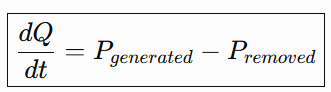

Q=Thermal capacitance X Stator winding temperature

In [1]:
!pip -q install kaggle
!pip -q install shap xgboost lightgbm

In [2]:
import os

os.environ["KAGGLE_API_TOKEN"] = "KGAT_c7275e11cb1c90653f2b71f4db704b79"

print("Kaggle API token configured.")

Kaggle API token configured.


In [3]:
!kaggle datasets download -d wkirgsn/electric-motor-temperature

Dataset URL: https://www.kaggle.com/datasets/wkirgsn/electric-motor-temperature
License(s): CC-BY-SA-4.0




  0%|          | 0.00/117M [00:00<?, ?B/s]
  1%|          | 1.00M/117M [00:01<02:30, 805kB/s]
  2%|▏         | 2.00M/117M [00:01<01:18, 1.53MB/s]
  3%|▎         | 3.00M/117M [00:01<00:49, 2.43MB/s]
  3%|▎         | 4.00M/117M [00:01<00:34, 3.39MB/s]
  4%|▍         | 5.00M/117M [00:01<00:26, 4.36MB/s]
  5%|▌         | 6.00M/117M [00:02<00:30, 3.85MB/s]
  7%|▋         | 8.00M/117M [00:02<00:23, 4.77MB/s]
  8%|▊         | 9.00M/117M [00:02<00:20, 5.53MB/s]
  9%|▊         | 10.0M/117M [00:03<00:25, 4.32MB/s]
 10%|█         | 12.0M/117M [00:03<00:21, 5.16MB/s]
 11%|█         | 13.0M/117M [00:03<00:21, 5.08MB/s]
 12%|█▏        | 14.0M/117M [00:03<00:20, 5.27MB/s]
 13%|█▎        | 15.0M/117M [00:03<00:20, 5.21MB/s]
 14%|█▎        | 16.0M/117M [00:04<00:20, 5.17MB/s]
 15%|█▍        | 17.0M/117M [00:04<00:26, 4.00MB/s]
 16%|█▋        | 19.0M/117M [00:04<00:22, 4.64MB/s]
 17%|█▋        | 20.0M/117M [00:05<00:20, 4.91MB/s]
 18%|█▊        | 21.0M/117M [00:05<00:19, 5.06MB/s]
 19%|█▉        | 22.0

In [4]:
import zipfile

with zipfile.ZipFile("electric-motor-temperature.zip", "r") as zip_ref:
    zip_ref.extractall()

print("Dataset extracted successfully.")

Dataset extracted successfully.


In [5]:
import os

os.listdir()

['.git',
 '.gitignore',
 'dataset',
 'electric-motor-temperature.zip',
 'Explainability',
 'figures',
 'measures_v2.csv',
 'models',
 'PIML (1).ipynb',
 'PIML PMSM Stator Winding Temperature Prediction.ipynb',
 'PIML_Explainable_AI.ipynb',
 'PIML_PISM_Research_Report.pdf',
 'PIML_PMSM_Research_Report.tex',
 'README.md']

In [6]:
import pandas as pd

# Load the PMSM dataset
df = pd.read_csv("measures_v2.csv")

print("Dataset Loaded Successfully!\n")
print("Shape:", df.shape)

df.head()

Dataset Loaded Successfully!

Shape: (1330816, 13)


,u_q,coolant,stator_winding,u_d,stator_tooth,motor_speed,i_d,i_q,pm,stator_yoke,ambient,torque,profile_id
0,-0.450682,18.805172,19.086670,-0.350055,18.293219,0.002866,0.004419,0.000328,24.554214,18.316547,19.850691,0.187101,17
1,-0.325737,18.818571,19.092390,-0.305803,18.294807,0.000257,0.000606,-0.000785,24.538078,18.314955,19.850672,0.245417,17
2,-0.440864,18.828770,19.089380,-0.372503,18.294094,0.002355,0.001290,0.000386,24.544693,18.326307,19.850657,0.176615,17
3,-0.327026,18.835567,19.083031,-0.316199,18.292542,0.006105,0.000026,0.002046,24.554018,18.330833,19.850647,0.238303,17
4,-0.471150,18.857033,19.082525,-0.332272,18.291428,0.003133,-0.064317,0.037184,24.565397,18.326662,19.850639,0.208197,17


In [7]:
print(df.columns.tolist())

['u_q', 'coolant', 'stator_winding', 'u_d', 'stator_tooth', 'motor_speed', 'i_d', 'i_q', 'pm', 'stator_yoke', 'ambient', 'torque', 'profile_id']


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1330816 entries, 0 to 1330815
Data columns (total 13 columns):
 #   Column          Non-Null Count    Dtype  
---  ------          --------------    -----  
 0   u_q             1330816 non-null  float64
 1   coolant         1330816 non-null  float64
 2   stator_winding  1330816 non-null  float64
 3   u_d             1330816 non-null  float64
 4   stator_tooth    1330816 non-null  float64
 5   motor_speed     1330816 non-null  float64
 6   i_d             1330816 non-null  float64
 7   i_q             1330816 non-null  float64
 8   pm              1330816 non-null  float64
 9   stator_yoke     1330816 non-null  float64
 10  ambient         1330816 non-null  float64
 11  torque          1330816 non-null  float64
 12  profile_id      1330816 non-null  int64  
dtypes: float64(12), int64(1)
memory usage: 132.0 MB


In [9]:
df.isnull().sum()

u_q               0
coolant           0
stator_winding    0
u_d               0
stator_tooth      0
motor_speed       0
i_d               0
i_q               0
pm                0
stator_yoke       0
ambient           0
torque            0
profile_id        0
dtype: int64

In [10]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
u_q,1330816.0,54.279005,44.173234,-25.290930,12.069925,48.938181,90.034393,133.036994
coolant,1330816.0,36.229995,21.786149,10.623751,18.698135,26.900141,49.857487,101.598512
stator_winding,1330816.0,66.342745,28.672061,18.585815,42.787957,65.110129,88.141137,141.362885
u_d,1330816.0,-25.133809,63.091972,-131.530411,-78.690904,-7.429755,1.470271,131.469788
stator_tooth,1330816.0,56.878582,22.952233,18.133976,38.416012,56.036345,75.586682,111.946423
motor_speed,1330816.0,2202.080728,1859.663350,-275.549144,317.110665,1999.976685,3760.639058,6000.015137
i_d,1330816.0,-68.716810,64.933233,-278.003632,-115.406060,-51.093763,-2.979688,0.051897
i_q,1330816.0,37.412782,92.181880,-293.426793,1.095863,15.774007,100.612150,301.707855
pm,1330816.0,58.506776,19.001498,20.856956,43.151582,60.266287,72.008371,113.606628
stator_yoke,1330816.0,48.187965,19.991004,18.076689,31.990333,45.625509,61.460828,101.147964


In [11]:
data = df.copy()

print("Working copy created.")

Working copy created.


***Physics-Oriented Exploratory Data Analysis (EDA)***

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("ggplot")
plt.rcParams["figure.figsize"] = (10,6)
sns.set_theme(style="whitegrid")

print("Visualization libraries loaded successfully.")

Visualization libraries loaded successfully.


In [13]:
print("Rows :", df.shape[0])
print("Columns :", df.shape[1])

df.head()

Rows : 1330816
Columns : 13


,u_q,coolant,stator_winding,u_d,stator_tooth,motor_speed,i_d,i_q,pm,stator_yoke,ambient,torque,profile_id
0,-0.450682,18.805172,19.086670,-0.350055,18.293219,0.002866,0.004419,0.000328,24.554214,18.316547,19.850691,0.187101,17
1,-0.325737,18.818571,19.092390,-0.305803,18.294807,0.000257,0.000606,-0.000785,24.538078,18.314955,19.850672,0.245417,17
2,-0.440864,18.828770,19.089380,-0.372503,18.294094,0.002355,0.001290,0.000386,24.544693,18.326307,19.850657,0.176615,17
3,-0.327026,18.835567,19.083031,-0.316199,18.292542,0.006105,0.000026,0.002046,24.554018,18.330833,19.850647,0.238303,17
4,-0.471150,18.857033,19.082525,-0.332272,18.291428,0.003133,-0.064317,0.037184,24.565397,18.326662,19.850639,0.208197,17


In [14]:
print(df.dtypes)

u_q               float64
coolant           float64
stator_winding    float64
u_d               float64
stator_tooth      float64
motor_speed       float64
i_d               float64
i_q               float64
pm                float64
stator_yoke       float64
ambient           float64
torque            float64
profile_id          int64
dtype: object


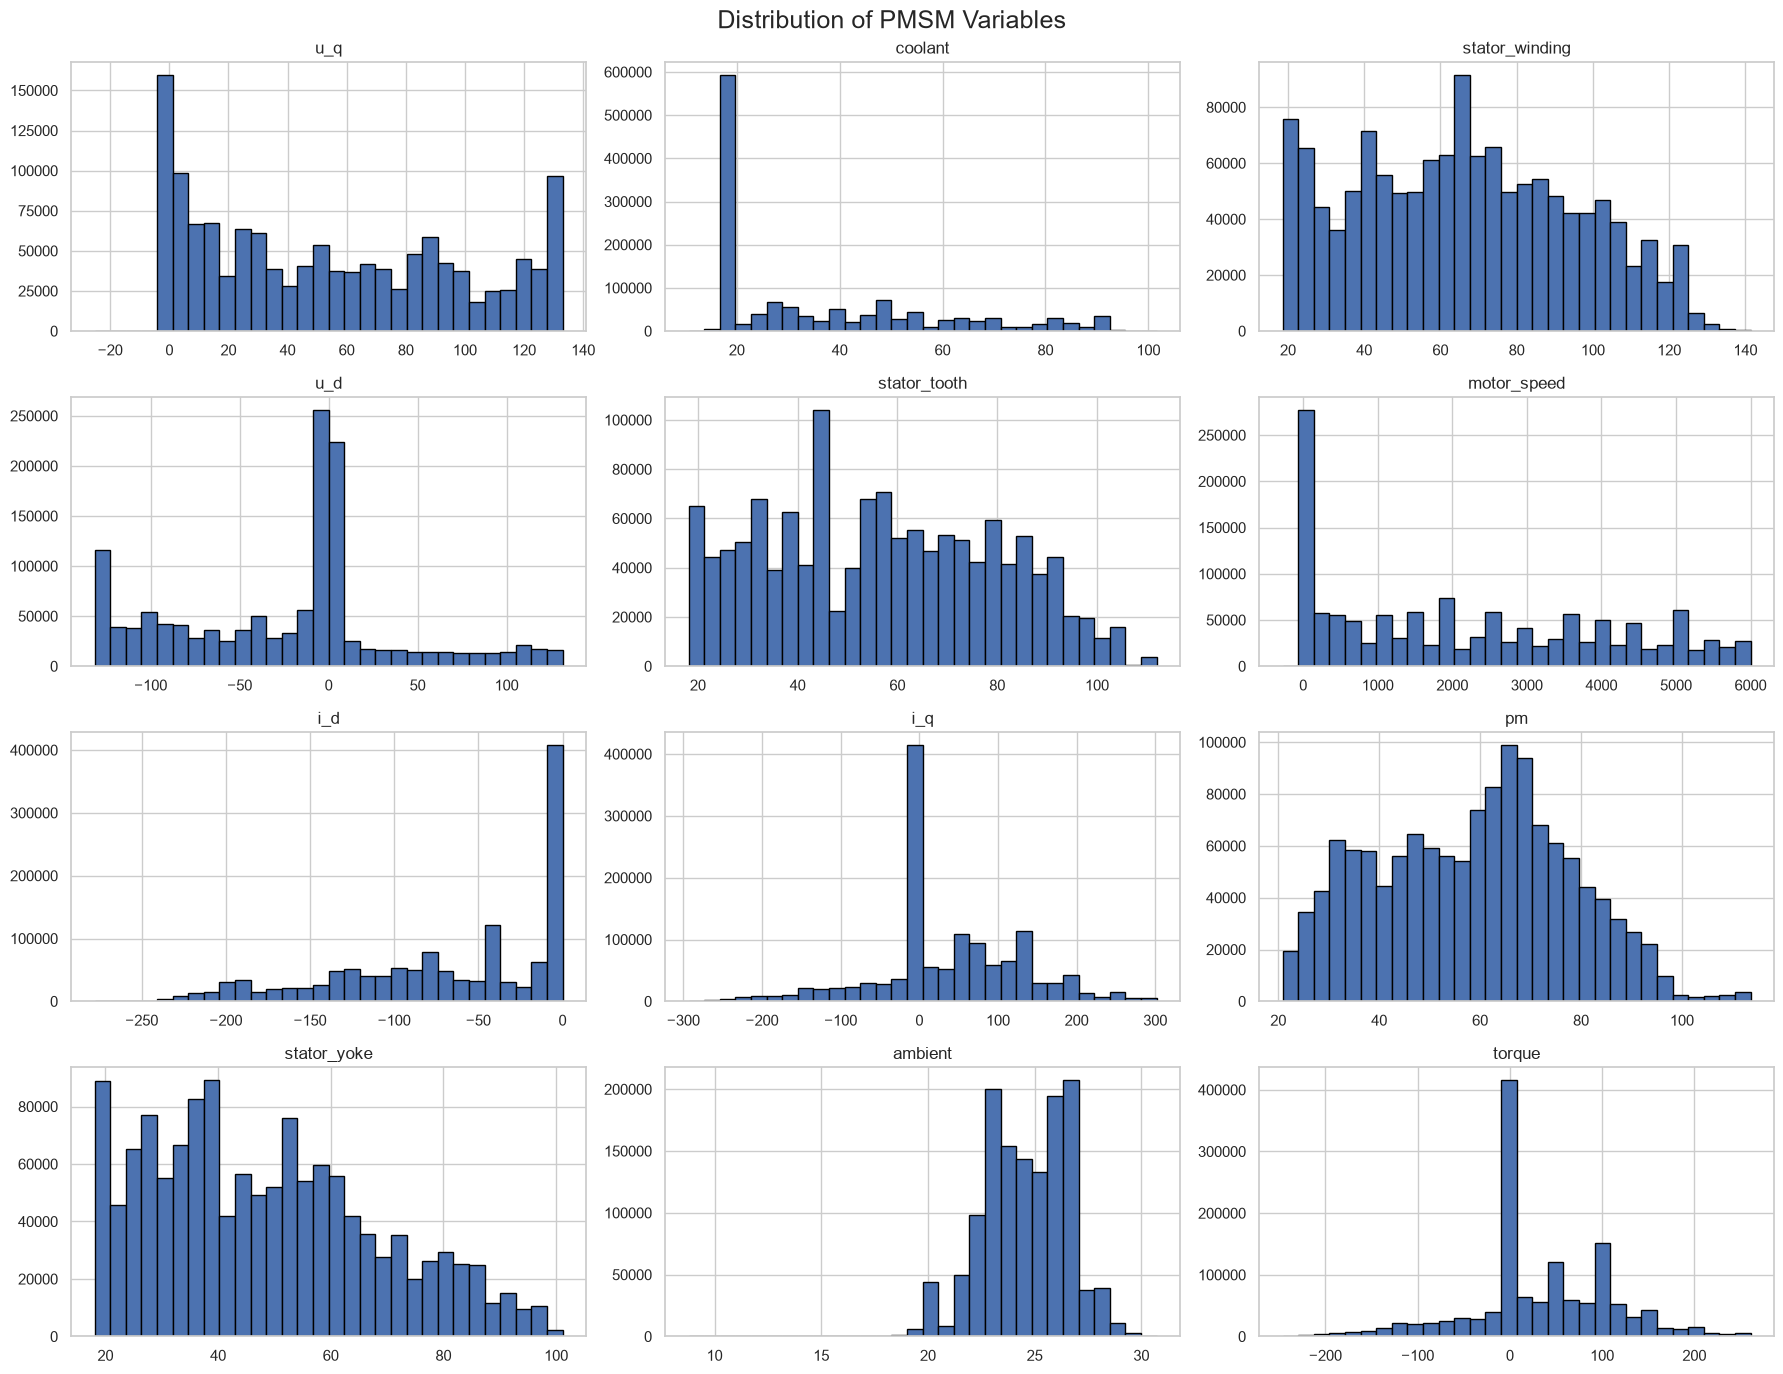

In [15]:
numerical_cols = [col for col in df.columns if col != "profile_id"]

df[numerical_cols].hist(
    bins=30,
    figsize=(18,14),
    edgecolor="black"
)

plt.suptitle("Distribution of PMSM Variables", fontsize=18)
plt.tight_layout()
plt.show()

*indicate the range of operating conditions.\
Current distributions\
Voltage distributions\
Temperature distributions\
Speed distribution\
Torque distribution

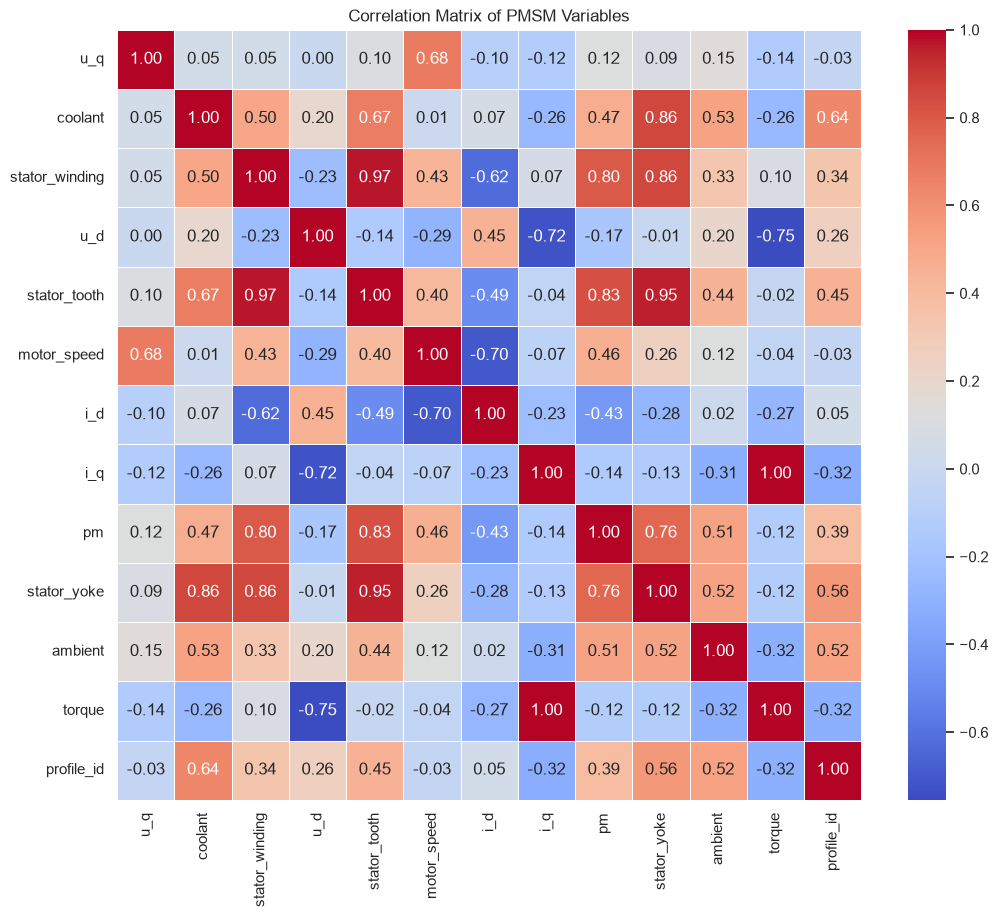

In [16]:
plt.figure(figsize=(12,10))

corr = df.corr(numeric_only=True)

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Matrix of PMSM Variables")
plt.show()

The correlation matrix helps identify physically meaningful relationships.

stator_winding ↔ stator_tooth → very high positive correlation.\
stator_winding ↔ stator_yoke → high positive correlation.\
stator_winding ↔ coolant → positive correlation.\
stator_winding ↔ ambient → positive correlation.

These arise because heat is conducted through adjacent motor components.

1.Current vs Stator Temperature

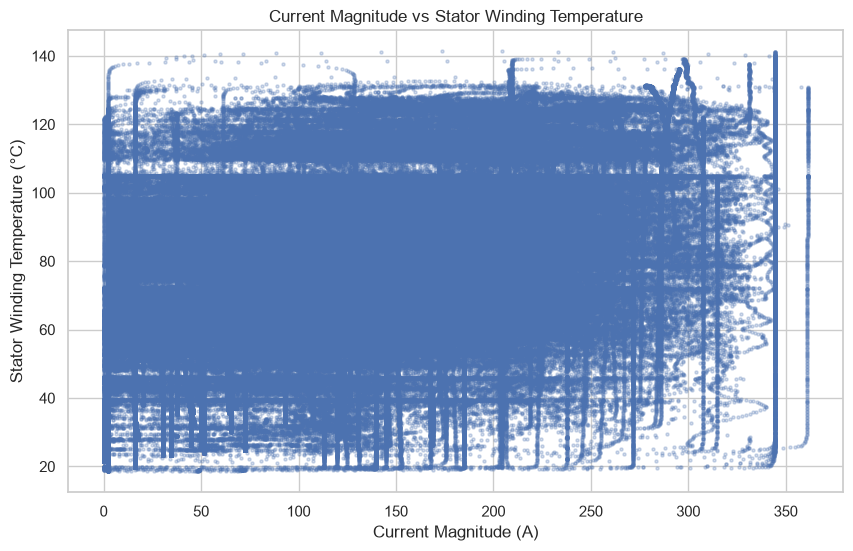

In [17]:
current = (df["i_d"]**2 + df["i_q"]**2)**0.5

plt.figure(figsize=(10,6))

plt.scatter(
    current,
    df["stator_winding"],
    alpha=0.25,
    s=5
)

plt.xlabel("Current Magnitude (A)")
plt.ylabel("Stator Winding Temperature (°C)")
plt.title("Current Magnitude vs Stator Winding Temperature")

plt.show()

*This plot confirms that current is a major driver of stator heating, but it is not sufficient by itself to explain the temperature.

2. Motor Speed vs Stator Temperature

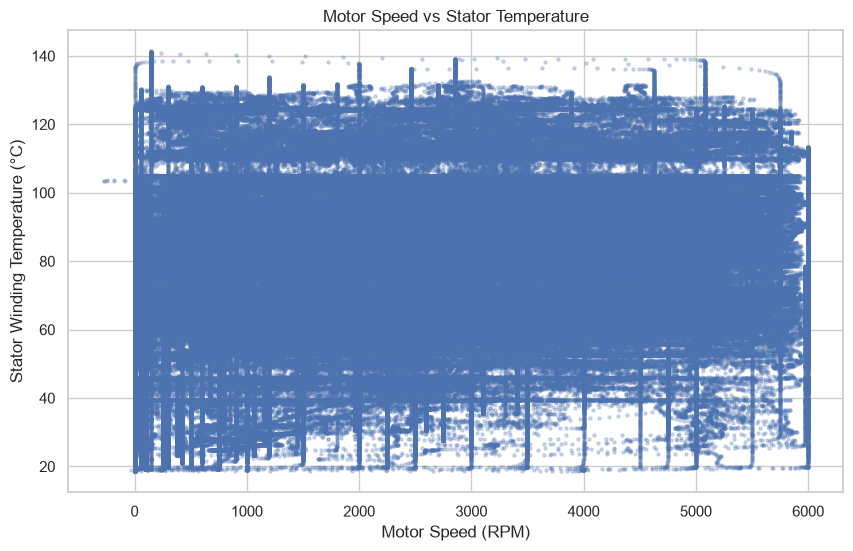

In [18]:
plt.figure(figsize=(10,6))

plt.scatter(
    df["motor_speed"],
    df["stator_winding"],
    alpha=0.25,
    s=5
)

plt.xlabel("Motor Speed (RPM)")
plt.ylabel("Stator Winding Temperature (°C)")
plt.title("Motor Speed vs Stator Temperature")

plt.show()

*Motor speed influences stator temperature indirectly by increasing iron losses and mechanical losses. However, the scatter plot shows that speed alone is not a reliable predictor of temperature because the motor's thermal state is determined by the combined effects of copper losses, iron losses, mechanical losses, cooling conditions, and thermal inertia. Consequently, identical motor speeds can correspond to very different stator temperatures depending on the electrical load and the recent operating history.

3. Torque vs Stator Temperature

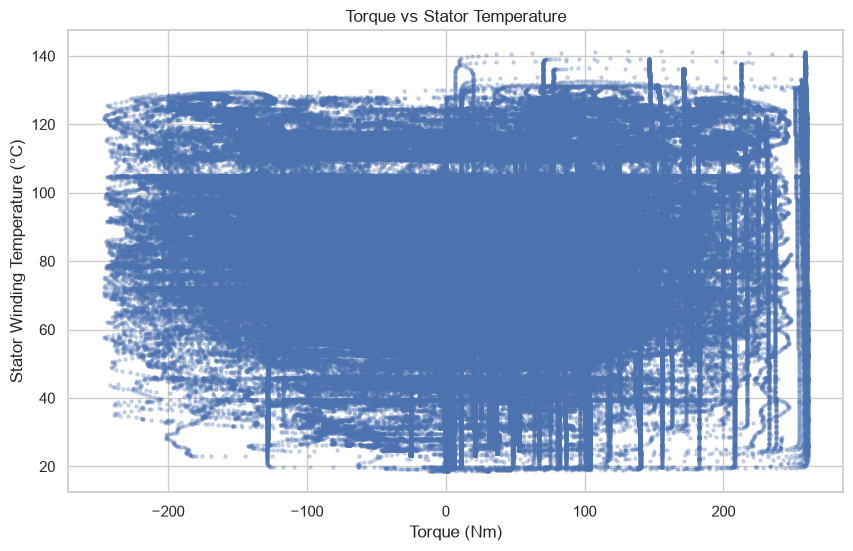

In [19]:
plt.figure(figsize=(10,6))

plt.scatter(
    df["torque"],
    df["stator_winding"],
    alpha=0.25,
    s=5
)

plt.xlabel("Torque (Nm)")
plt.ylabel("Stator Winding Temperature (°C)")
plt.title("Torque vs Stator Temperature")

plt.show()

*The key point is that torque is not a direct heat source. Instead, it increases the electrical current required by the motor, which then increases copper losses, the dominant source of stator heating.

4. Coolant Temperature vs Stator Temperature

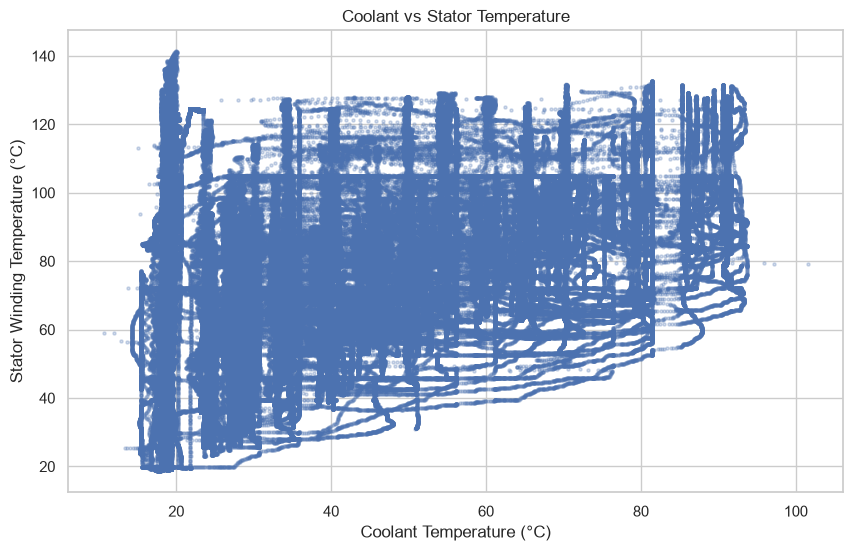

In [20]:
plt.figure(figsize=(10,6))

plt.scatter(
    df["coolant"],
    df["stator_winding"],
    alpha=0.25,
    s=5
)

plt.xlabel("Coolant Temperature (°C)")
plt.ylabel("Stator Winding Temperature (°C)")
plt.title("Coolant vs Stator Temperature")

plt.show()

*Unlike current, speed, and torque, coolant temperature is directly related to the motor's cooling mechanism. This plot gives evidence about heat dissipation, which is one of the two sides of the thermal energy balance equation. heat dissipation

5. Ambient Temperature vs Stator Temperature

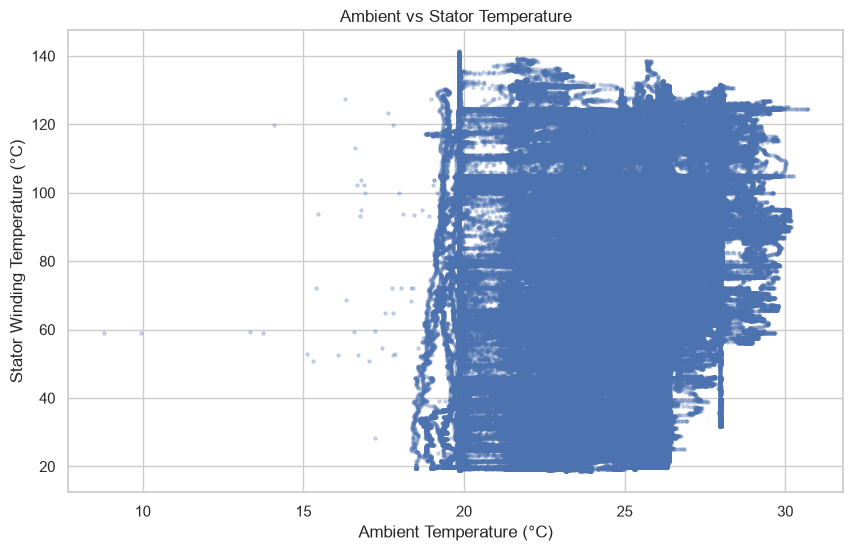

In [21]:
plt.figure(figsize=(10,6))

plt.scatter(
    df["ambient"],
    df["stator_winding"],
    alpha=0.25,
    s=5
)

plt.xlabel("Ambient Temperature (°C)")
plt.ylabel("Stator Winding Temperature (°C)")
plt.title("Ambient vs Stator Temperature")

plt.show()

*Ambient temperature sets the boundary condition for heat transfer.

Higher ambient temperature reduces the cooling gradient, leading to higher operating temperatures.

Unlike current, speed, or torque, ambient temperature does not generate heat. Instead, it determines the environment into which the motor rejects heat. In thermal engineering, it is treated as a boundary condition for the heat-transfer problem.

Pairplot (Sampled Data)

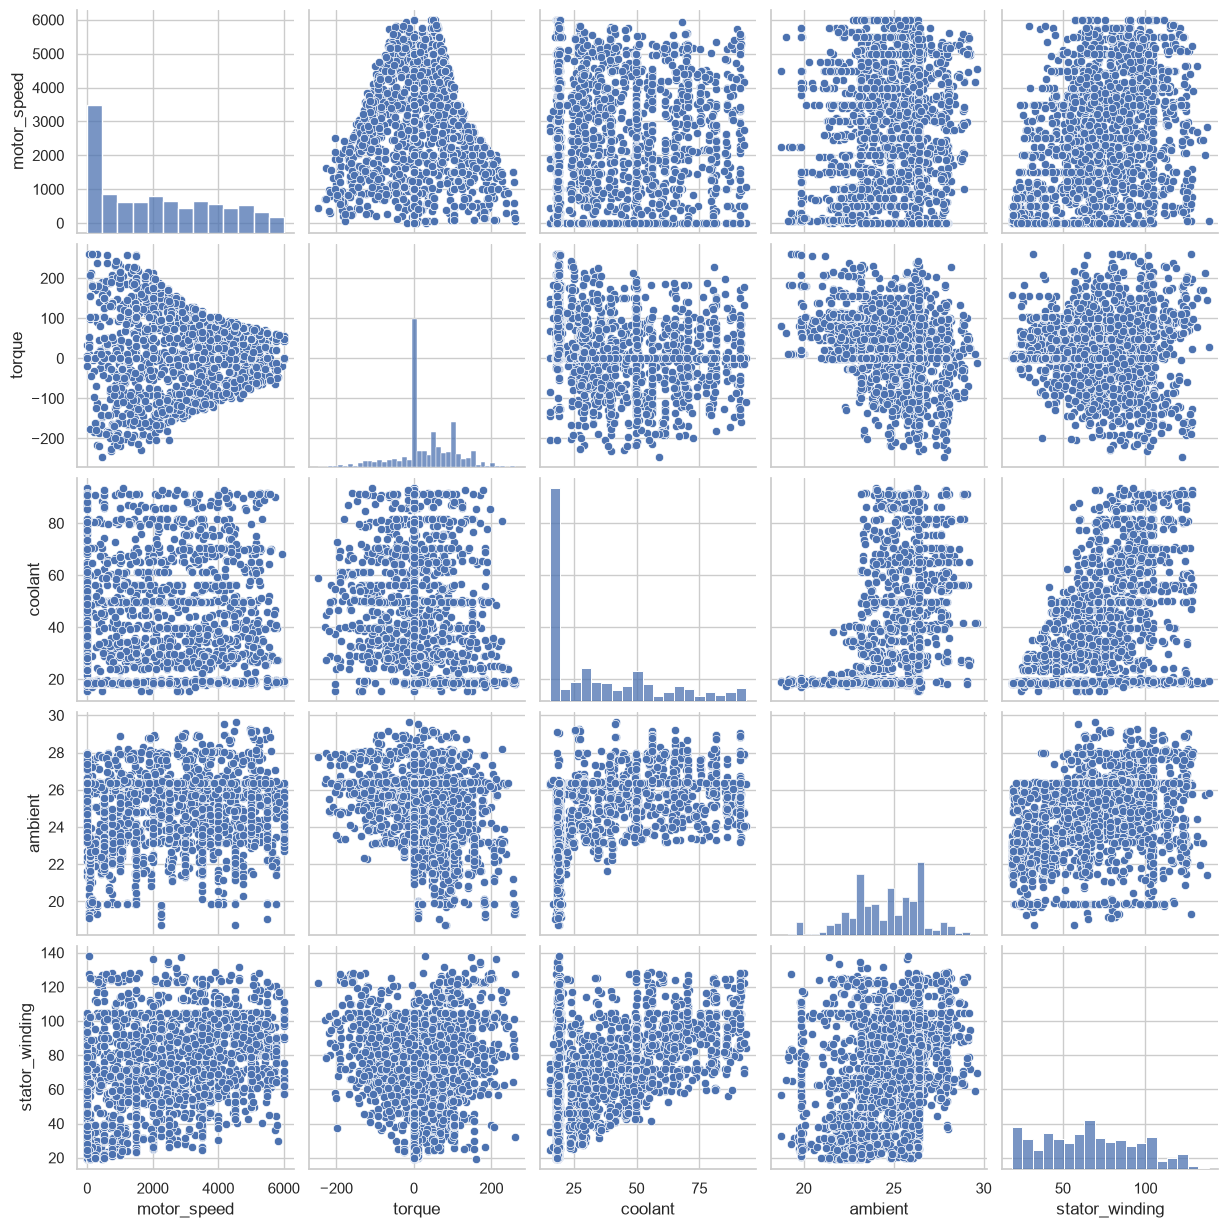

In [22]:
sample_df = df.sample(3000, random_state=42)

sns.pairplot(
    sample_df[
        [
            "motor_speed",
            "torque",
            "coolant",
            "ambient",
            "stator_winding"
        ]
    ]
)

plt.show()

*This visualizes pairwise relationships without overwhelming the plotting library.

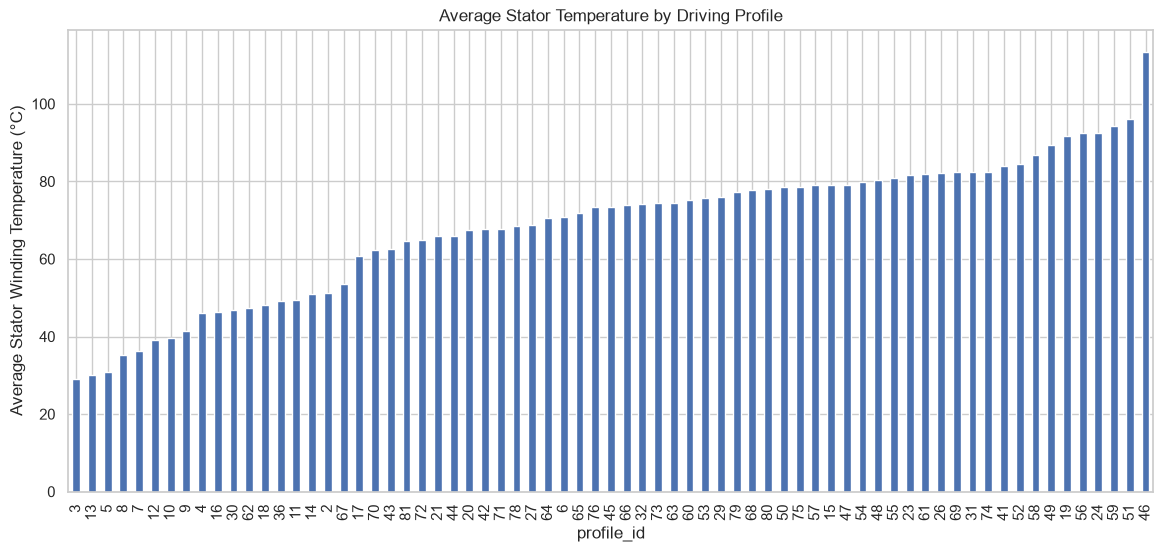

In [23]:
profile_mean = df.groupby("profile_id")["stator_winding"].mean().sort_values()

plt.figure(figsize=(14,6))

profile_mean.plot(kind="bar")

plt.ylabel("Average Stator Winding Temperature (°C)")
plt.title("Average Stator Temperature by Driving Profile")

plt.show()

In [24]:
print("="*60)
print("Physics-Oriented EDA Summary")
print("="*60)

print("\n1. Copper losses increase with current magnitude.")
print("2. Higher motor speed tends to increase iron and mechanical losses.")
print("3. Higher torque requires higher current, increasing heat generation.")
print("4. Elevated coolant temperature reduces cooling effectiveness.")
print("5. Ambient temperature influences the external thermal boundary.")
print("6. Stator winding, tooth, and yoke temperatures are strongly coupled through heat conduction.")

Physics-Oriented EDA Summary

1. Copper losses increase with current magnitude.
2. Higher motor speed tends to increase iron and mechanical losses.
3. Higher torque requires higher current, increasing heat generation.
4. Elevated coolant temperature reduces cooling effectiveness.
5. Ambient temperature influences the external thermal boundary.
6. Stator winding, tooth, and yoke temperatures are strongly coupled through heat conduction.


***Physics-Based Feature Engineering***

In [25]:
physics_df = df.copy()

print("Working dataset created.")

Working dataset created.


In [26]:
import numpy as np

physics_df["current_magnitude"] = np.sqrt(
    physics_df["i_d"]**2 +
    physics_df["i_q"]**2
)

physics_df[["i_d","i_q","current_magnitude"]].head()

,i_d,i_q,current_magnitude
0,0.004419,0.000328,0.004431
1,0.000606,-0.000785,0.000992
2,0.001290,0.000386,0.001346
3,0.000026,0.002046,0.002046
4,-0.064317,0.037184,0.074292


*Copper losses depend on the total current

In [27]:
physics_df["voltage_magnitude"] = np.sqrt(
    physics_df["u_d"]**2 +
    physics_df["u_q"]**2
)

physics_df[["u_d","u_q","voltage_magnitude"]].head()

,u_d,u_q,voltage_magnitude
0,-0.350055,-0.450682,0.570659
1,-0.305803,-0.325737,0.446789
2,-0.372503,-0.440864,0.577165
3,-0.316199,-0.327026,0.454893
4,-0.332272,-0.471150,0.576530


*Voltage magnitude represents the electrical excitation of the motor.

In [28]:
physics_df["electrical_power"] = 1.5 * (
    physics_df["u_d"]*physics_df["i_d"] +
    physics_df["u_q"]*physics_df["i_q"]
)

physics_df["electrical_power"].describe()

count    1.330816e+06
mean     7.630838e+03
std      1.858304e+04
min     -4.651746e+04
25%     -4.693924e+00
50%      1.457590e+03
75%      2.122546e+04
max      5.247164e+04
Name: electrical_power, dtype: float64

*This approximates the instantaneous electrical input power to the motor.

In [29]:
physics_df["omega"] = (
    2*np.pi*
    physics_df["motor_speed"]/60
)

physics_df["omega"].head()

0    0.000300
1    0.000027
2    0.000247
3    0.000639
4    0.000328
Name: omega, dtype: float64

*Mechanical power calculations require angular velocity in SI units.

In [30]:
physics_df["mechanical_power"] = (
    physics_df["torque"] *
    physics_df["omega"]
)

physics_df["mechanical_power"].describe()

count    1.330816e+06
mean     6.513603e+03
std      1.858097e+04
min     -5.526779e+04
25%     -2.693797e+01
50%      1.027488e+03
75%      2.043910e+04
max      4.961819e+04
Name: mechanical_power, dtype: float64

*This represents the useful mechanical power produced by the motor.

In [31]:
physics_df["copper_loss_proxy"] = (
    physics_df["current_magnitude"]**2
)

physics_df["copper_loss_proxy"].describe()

count    1.330816e+06
mean     1.883553e+04
std      2.163620e+04
min      1.538376e-09
25%      1.399061e+02
50%      1.223679e+04
75%      2.963283e+04
max      1.306933e+05
Name: copper_loss_proxy, dtype: float64

*This feature captures the dominant dependence of copper losses on current.

In [32]:
physics_df["speed_squared"] = (
    physics_df["motor_speed"]**2
)

physics_df["speed_squared"].head()

0    8.211479e-06
1    6.593683e-08
2    5.545890e-06
3    3.726694e-05
4    9.814579e-06
Name: speed_squared, dtype: float64

*This provides a proxy for speed-dependent losses.

In [33]:
physics_df["deltaT_coolant"] = (
    physics_df["stator_winding"] -
    physics_df["coolant"]
)

physics_df["deltaT_coolant"].describe()

count    1.330816e+06
mean     3.011275e+01
std      2.580754e+01
min     -3.021466e+01
25%      9.662164e+00
50%      2.612145e+01
75%      4.398553e+01
max      1.213887e+02
Name: deltaT_coolant, dtype: float64

*This is the driving force for heat transfer to the coolant.

In [34]:
physics_df["deltaT_ambient"] = (
    physics_df["stator_winding"] -
    physics_df["ambient"]
)

physics_df["deltaT_ambient"].describe()

count    1.330816e+06
mean     4.177749e+01
std      2.808811e+01
min     -6.425226e+00
25%      1.887552e+01
50%      4.079801e+01
75%      6.243310e+01
max      1.215123e+02
Name: deltaT_ambient, dtype: float64

*This approximates heat loss to the surrounding environment.

In [35]:
# Sampling interval (2 Hz)
dt = 0.5

physics_df["dT_dt"] = (
    physics_df
    .groupby("profile_id")["stator_winding"]
    .diff() / dt
)

# Fill the first value of each profile with 0
physics_df["dT_dt"] = physics_df["dT_dt"].fillna(0)

physics_df["dT_dt"].describe()

count    1.330816e+06
mean     2.755118e-03
std      1.550901e-01
min     -2.751526e+00
25%     -5.063645e-02
50%     -1.156144e-03
75%      3.680420e-02
max      2.787876e+00
Name: dT_dt, dtype: float64

*The dataset is sampled at 2 Hz.

In [36]:
physics_features = [
    "current_magnitude",
    "voltage_magnitude",
    "electrical_power",
    "omega",
    "mechanical_power",
    "copper_loss_proxy",
    "speed_squared",
    "deltaT_coolant",
    "deltaT_ambient",
    "dT_dt"
]

physics_df[physics_features].head()

,current_magnitude,voltage_magnitude,electrical_power,omega,mechanical_power,copper_loss_proxy,speed_squared,deltaT_coolant,deltaT_ambient,dT_dt
0,0.004431,0.570659,-0.002542,0.000300,0.000056,1.963642e-05,8.211479e-06,0.281498,-0.764021,0.000000
1,0.000992,0.446789,0.000106,0.000027,0.000007,9.838601e-07,6.593683e-08,0.273819,-0.758282,0.011440
2,0.001346,0.577165,-0.000976,0.000247,0.000044,1.812393e-06,5.545890e-06,0.260611,-0.761276,-0.006020
3,0.002046,0.454893,-0.001016,0.000639,0.000152,4.185383e-06,3.726694e-05,0.247463,-0.767616,-0.012699
4,0.074292,0.576530,0.005777,0.000328,0.000068,5.519281e-03,9.814579e-06,0.225492,-0.768114,-0.001011


In [37]:
corr = (
    physics_df[
        physics_features + ["stator_winding"]
    ]
    .corr()["stator_winding"]
    .sort_values(ascending=False)
)

print(corr)

stator_winding       1.000000
deltaT_ambient       0.997900
deltaT_coolant       0.684825
current_magnitude    0.571575
copper_loss_proxy    0.532873
omega                0.432034
voltage_magnitude    0.422587
speed_squared        0.401841
electrical_power     0.267836
mechanical_power     0.232068
dT_dt               -0.004141
Name: stator_winding, dtype: float64


In [38]:
physics_df.to_csv(
    "physics_engineered_pmsm.csv",
    index=False
)

print("Physics-enhanced dataset saved successfully.")

Physics-enhanced dataset saved successfully.


**A conventional machine learning model would use the raw sensor values directly. Here, we've transformed those measurements into quantities that correspond to the governing equations of electrical power, mechanical power, Joule heating, and heat transfer. These engineered features embed physical knowledge into the learning process, improving both interpretability and consistency with the underlying thermal behavior of the PMSM.

***Physics Residual***(first attempt)

In [39]:
physics_df["heat_generation_proxy"] = (
    physics_df["copper_loss_proxy"] +
    physics_df["speed_squared"]
)

physics_df["heat_generation_proxy"].describe()

count    1.330816e+06
mean     8.326340e+06
std      9.961701e+06
min      2.727395e-08
25%      1.415402e+05
50%      3.999923e+06
75%      1.416278e+07
max      3.603755e+07
Name: heat_generation_proxy, dtype: float64

*represents the dominant electrical and speed-dependent heating effects.

In [40]:
physics_df["cooling_proxy"] = (
    physics_df["deltaT_coolant"]
)

physics_df["cooling_proxy"].describe()

count    1.330816e+06
mean     3.011275e+01
std      2.580754e+01
min     -3.021466e+01
25%      9.662164e+00
50%      2.612145e+01
75%      4.398553e+01
max      1.213887e+02
Name: cooling_proxy, dtype: float64

Since
R
th
is unknown,
Approximation
P
cooling
∝(T−T
coolant
)

In [41]:
physics_df["thermal_storage_proxy"] = (
    physics_df["dT_dt"]
)

physics_df["thermal_storage_proxy"].describe()

count    1.330816e+06
mean     2.755118e-03
std      1.550901e-01
min     -2.751526e+00
25%     -5.063645e-02
50%     -1.156144e-03
75%      3.680420e-02
max      2.787876e+00
Name: thermal_storage_proxy, dtype: float64

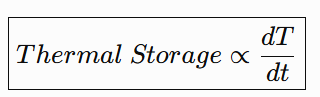

In [42]:
physics_df["physics_residual"] = (
    physics_df["heat_generation_proxy"]
    -
    physics_df["cooling_proxy"]
    -
    physics_df["thermal_storage_proxy"]
)

physics_df["physics_residual"].describe()

count    1.330816e+06
mean     8.326310e+06
std      9.961689e+06
min     -1.087476e+02
25%      1.415322e+05
50%      3.999914e+06
75%      1.416276e+07
max      3.603746e+07
Name: physics_residual, dtype: float64

In ideal system, residual=0

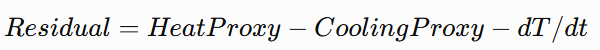

Small residual-> Measured data closely follows the thermal model.

Large residual-> Missing physics
or
measurement noise.

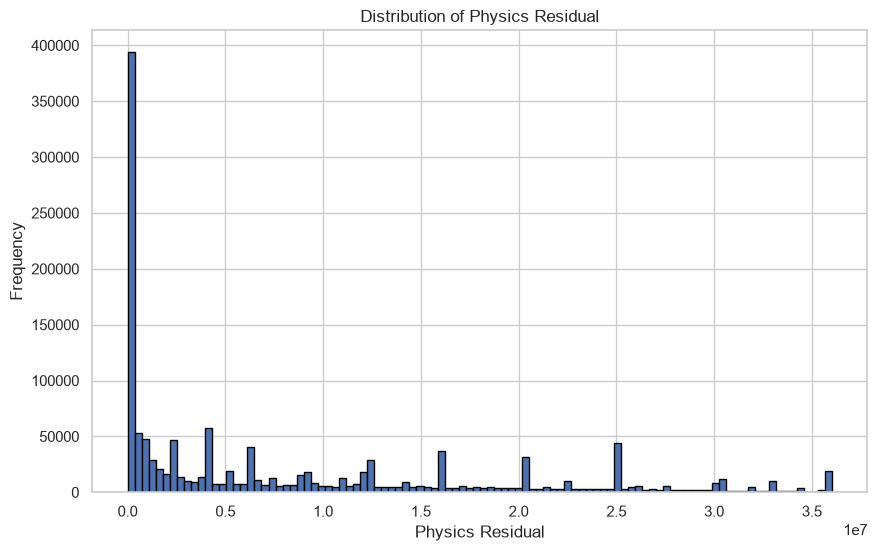

In [43]:
plt.figure(figsize=(10,6))

plt.hist(
    physics_df["physics_residual"],
    bins=100,
    edgecolor="black"
)

plt.title("Distribution of Physics Residual")

plt.xlabel("Physics Residual")

plt.ylabel("Frequency")

plt.show()

Most of the time, an electric motor does not undergo rapid acceleration or rapid thermal transients.

Instead, it spends much of its time operating under
nearly constant load,
nearly constant speed,
nearly constant current

Thermal equilibrium.

We ignored
temperature-dependent resistance,
winding resistance,
magnetic saturation.

Heat Generation
is much larger than
Cooling + Thermal Storage.

During
rapid acceleration,
regenerative braking, or
sudden load changes
the thermal balance becomes transient,
making the residual larger.

***Physics Residual***(second attempt)Estimation of Thermal Model Coefficients

grey-box thermal modeling

In [44]:
from sklearn.linear_model import LinearRegression

import numpy as np

import pandas as pd

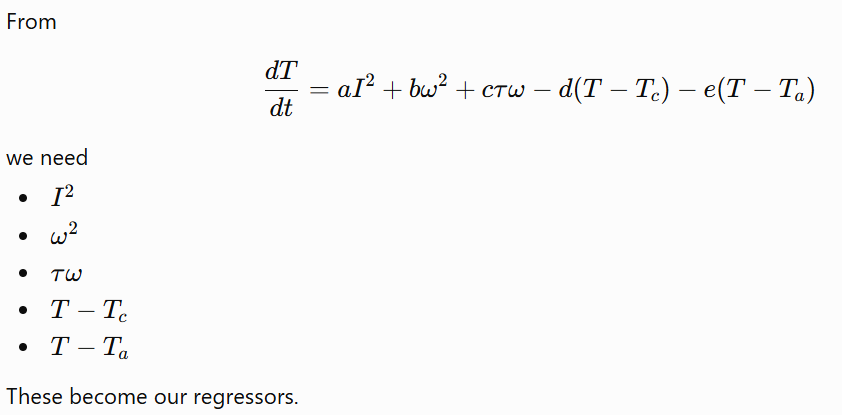

In [45]:
physics_df["I_squared"] = (
    physics_df["current_magnitude"]**2
)

physics_df["omega_squared"] = (
    physics_df["omega"]**2
)

physics_df["torque_omega"] = (
    physics_df["torque"] *
    physics_df["omega"]
)

physics_df["cooling_term"] = (
    physics_df["stator_winding"]
    -
    physics_df["coolant"]
)

physics_df["ambient_term"] = (
    physics_df["stator_winding"]
    -
    physics_df["ambient"]
)

In [46]:
X = physics_df[
[
    "I_squared",
    "omega_squared",
    "torque_omega",
    "cooling_term",
    "ambient_term"
]
]

y = physics_df["dT_dt"]

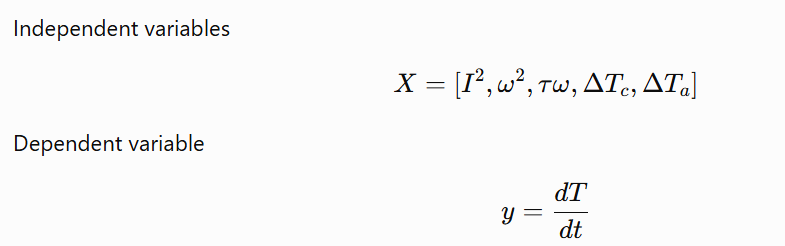

In [47]:
thermal_model = LinearRegression()

thermal_model.fit(X, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](5,)","[ 0., 0., 0.,-0.,-0.]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](5,)","['I_squared','omega_squared','torque_omega','cooling_term','ambient_term']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-0.001251
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,5
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,5


In [48]:
coefficients = pd.DataFrame({

"Term":X.columns,

"Estimated Coefficient":thermal_model.coef_

})

coefficients

,Term,Estimated Coefficient
0,I_squared,5.683198e-06
1,omega_squared,3.853862e-07
2,torque_omega,3.953898e-07
3,cooling_term,-3.728824e-03
4,ambient_term,-6.807425e-04


In [49]:
a,b,c,d,e = thermal_model.coef_

print("="*60)

print("Estimated Thermal Model")

print("="*60)

print(f"dT/dt = {a:.6e} * I²")

print(f"       + {b:.6e} * ω²")

print(f"       + {c:.6e} * τω")

print(f"       - {d:.6e} * (T-Tcoolant)")

print(f"       - {e:.6e} * (T-Tambient)")

Estimated Thermal Model
dT/dt = 5.683198e-06 * I²
       + 3.853862e-07 * ω²
       + 3.953898e-07 * τω
       - -3.728824e-03 * (T-Tcoolant)
       - -6.807425e-04 * (T-Tambient)


In [50]:
physics_df["predicted_dT_dt"] = thermal_model.predict(X)

physics_df[
[
"dT_dt",
"predicted_dT_dt"
]
].head()

,dT_dt,predicted_dT_dt
0,0.000000,-0.001780
1,0.011440,-0.001756
2,-0.006020,-0.001704
3,-0.012699,-0.001651
4,-0.001011,-0.001569


*The model predicts
how fast the stator temperature should increase
according to physics.

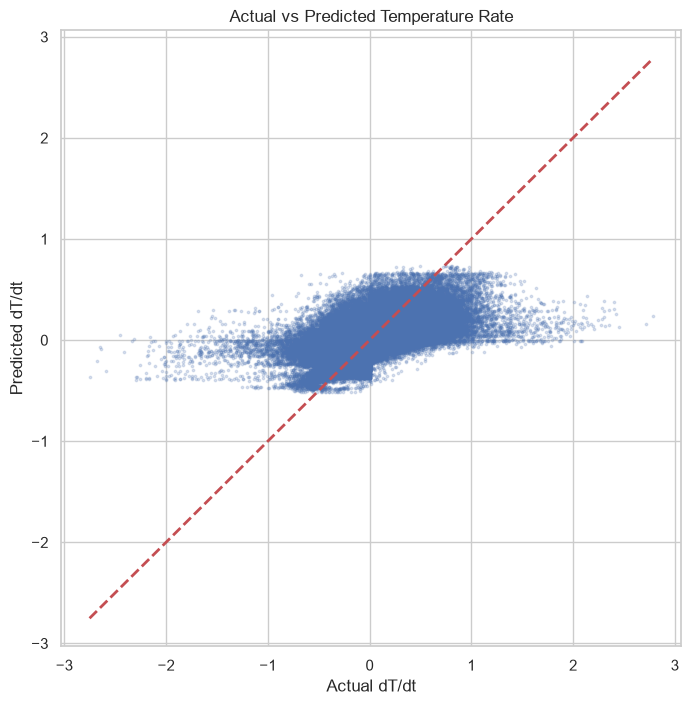

In [51]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,8))

plt.scatter(

physics_df["dT_dt"],

physics_df["predicted_dT_dt"],

alpha=0.2,

s=3

)

xmin=min(physics_df["dT_dt"])

xmax=max(physics_df["dT_dt"])

plt.plot(

[xmin,xmax],

[xmin,xmax],

'r--',

linewidth=2

)

plt.xlabel("Actual dT/dt")

plt.ylabel("Predicted dT/dt")

plt.title("Actual vs Predicted Temperature Rate")

plt.show()

**The present thermal model captures only part of the temperature dynamics.

***Improved Physics Model***

In [52]:
physics_df = physics_df.sort_values(
    ["profile_id"]
).reset_index(drop=True)

In [53]:
physics_df["T_prev"] = (
    physics_df
    .groupby("profile_id")["stator_winding"]
    .shift(1)
)

physics_df["T_prev"] = physics_df["T_prev"].fillna(
    physics_df["stator_winding"]
)

In [54]:
physics_df["I_prev"] = (
    physics_df
    .groupby("profile_id")["current_magnitude"]
    .shift(1)
)

physics_df["I_prev"] = physics_df["I_prev"].fillna(
    physics_df["current_magnitude"]
)

In [55]:
physics_df["omega_prev"] = (
    physics_df
    .groupby("profile_id")["omega"]
    .shift(1)
)

physics_df["omega_prev"] = physics_df["omega_prev"].fillna(
    physics_df["omega"]
)

In [56]:
physics_df["I2_T"] = (
    physics_df["I_squared"]
    *
    physics_df["stator_winding"]
)

In [57]:
physics_df["I2_cooling"] = (
    physics_df["I_squared"]
    *
    physics_df["cooling_term"]
)

In [58]:
physics_df["omega2_cooling"] = (
    physics_df["omega_squared"]
    *
    physics_df["cooling_term"]
)

In [59]:
physics_df["torque_cooling"] = (
    physics_df["torque_omega"]
    *
    physics_df["cooling_term"]
)

In [60]:
physics_df["cooling_squared"] = (
    physics_df["cooling_term"]**2
)

In [61]:
feature_columns = [

"I_squared",

"omega_squared",

"torque_omega",

"cooling_term",

"ambient_term",

"T_prev",

"I_prev",

"omega_prev",

"I2_T",

"I2_cooling",

"omega2_cooling",

"torque_cooling",

"cooling_squared"

]

X = physics_df[feature_columns]

y = physics_df["dT_dt"]

In [62]:
from sklearn.linear_model import LinearRegression

thermal_model = LinearRegression()

thermal_model.fit(X,y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](13,)","[ 0., 0.,-0.,..., 0., 0.,-0.]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](13,)","['I_squared','omega_squared','torque_omega',...,'omega2_cooling', 'torque_cooling','cooling_squared']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,0.01508
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,13
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,12


In [63]:
coef_df = pd.DataFrame({

"Feature":feature_columns,

"Coefficient":thermal_model.coef_

})

coef_df

,Feature,Coefficient
0,I_squared,5.300830e-06
1,omega_squared,2.981967e-08
2,torque_omega,-1.332436e-07
3,cooling_term,-4.195505e-03
4,ambient_term,-3.621305e-04
5,T_prev,-3.886825e-04
6,I_prev,-9.656095e-06
7,omega_prev,1.146992e-04
8,I2_T,8.685800e-09
9,I2_cooling,-2.181095e-09


In [64]:
physics_df["predicted_dT_dt"] = thermal_model.predict(X)

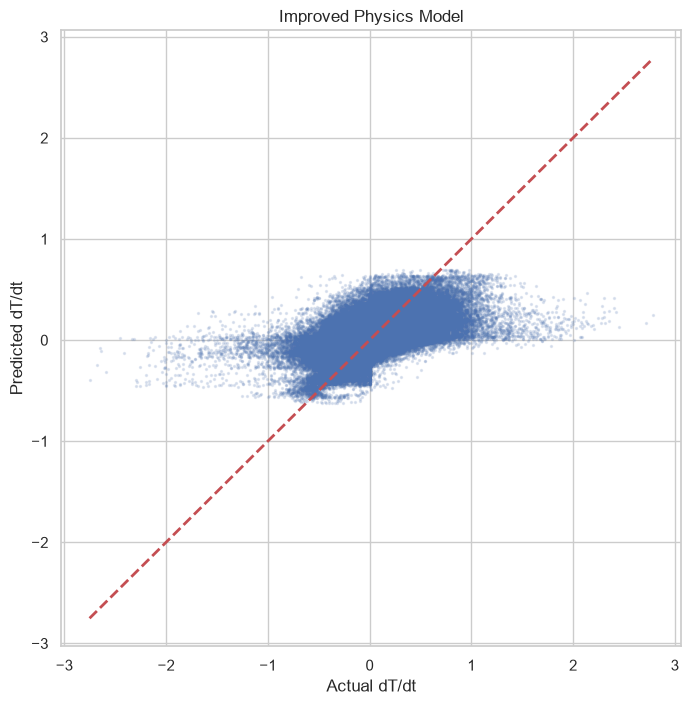

In [65]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,8))

plt.scatter(

physics_df["dT_dt"],

physics_df["predicted_dT_dt"],

alpha=0.15,

s=2

)

xmin=min(physics_df["dT_dt"])

xmax=max(physics_df["dT_dt"])

plt.plot(

[xmin,xmax],

[xmin,xmax],

'r--',

linewidth=2

)

plt.xlabel("Actual dT/dt")

plt.ylabel("Predicted dT/dt")

plt.title("Improved Physics Model")

plt.show()

In [66]:
from sklearn.metrics import r2_score

r2 = r2_score(

physics_df["dT_dt"],

physics_df["predicted_dT_dt"]

)

print("Improved Physics R² :",r2)

Improved Physics R² : 0.3363603743004774


In [67]:
physics_df["physics_residual"] = (

physics_df["dT_dt"]

-

physics_df["predicted_dT_dt"]

)

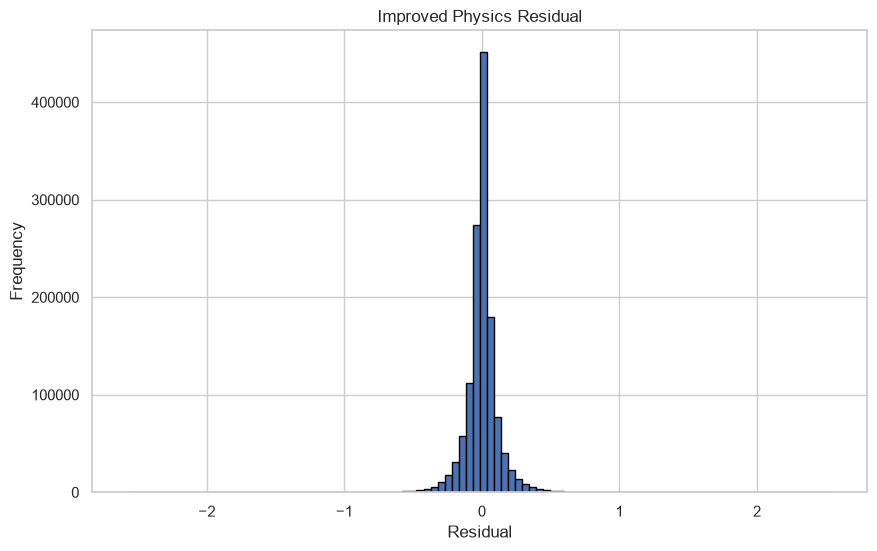

In [68]:
plt.figure(figsize=(10,6))

plt.hist(

physics_df["physics_residual"],

bins=100,

edgecolor="black"

)

plt.xlabel("Residual")

plt.ylabel("Frequency")

plt.title("Improved Physics Residual")

plt.show()

In [69]:
coef_df.sort_values("Coefficient", key=abs, ascending=False)

,Feature,Coefficient
3,cooling_term,-4.195505e-03
5,T_prev,-3.886825e-04
4,ambient_term,-3.621305e-04
7,omega_prev,1.146992e-04
6,I_prev,-9.656095e-06
0,I_squared,5.300830e-06
12,cooling_squared,-3.226163e-06
2,torque_omega,-1.332436e-07
1,omega_squared,2.981967e-08
11,torque_cooling,8.957131e-09


In [72]:
!pip install statsmodels

   ---------------------------------------- 0.0/9.6 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.6 MB ? eta -:--:--
   ---- ----------------------------------- 1.0/9.6 MB 3.6 MB/s eta 0:00:03
   ------- -------------------------------- 1.8/9.6 MB 3.5 MB/s eta 0:00:03
   ------------ --------------------------- 2.9/9.6 MB 3.9 MB/s eta 0:00:02
   --------------- ------------------------ 3.7/9.6 MB 4.0 MB/s eta 0:00:02
   ------------------ --------------------- 4.5/9.6 MB 4.1 MB/s eta 0:00:02
   ------------------------- -------------- 6.0/9.6 MB 4.5 MB/s eta 0:00:01
   ----------------------------- ---------- 7.1/9.6 MB 4.7 MB/s eta 0:00:01
   ----------------------------------- ---- 8.4/9.6 MB 4.8 MB/s eta 0:00:01
   ---------------------------------------- 9.6/9.6 MB 5.0 MB/s  0:00:02

   ---------------------------------------- 0/2 [patsy]
   ---------------------------------------- 0/2 [patsy]
   ---------------------------------------- 0/2 [patsy]
   ---------

In [73]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
import pandas as pd

X_vif = physics_df[feature_columns]

vif = pd.DataFrame({
    "Feature": X_vif.columns,
    "VIF": [
        variance_inflation_factor(X_vif.values, i)
        for i in range(X_vif.shape[1])
    ]
})

print(vif.sort_values("VIF", ascending=False))

            Feature        VIF
4      ambient_term  53.072559
0         I_squared  52.686067
8              I2_T  52.569960
5            T_prev  51.947580
12  cooling_squared  42.540589
9        I2_cooling  40.197739
1     omega_squared  35.472206
3      cooling_term  33.167515
7        omega_prev  32.138581
6            I_prev  29.159222
10   omega2_cooling  14.842972
11   torque_cooling  14.047004
2      torque_omega   7.595128


***Baseline Machine Learning***

In [74]:
import numpy as np
import pandas as pd

from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

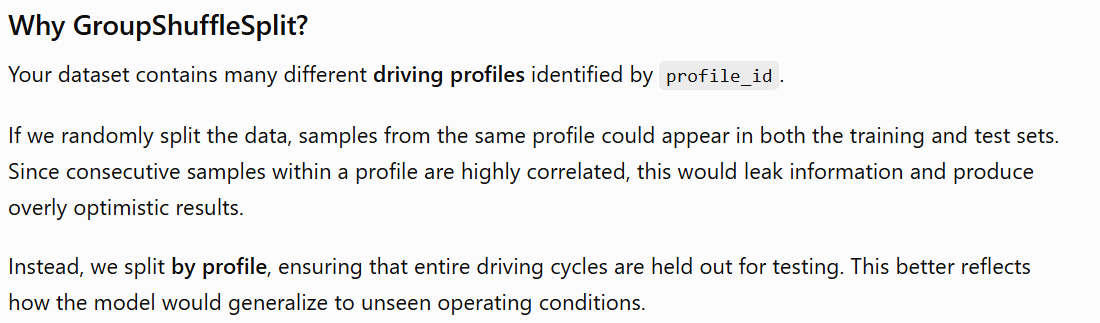

In [75]:
features = [

    "current_magnitude",

    "voltage_magnitude",

    "omega",

    "torque",

    "coolant",

    "ambient",

    "T_prev"

]

target = "stator_winding"

In [76]:
X = physics_df[features]
y = physics_df[target]
groups = physics_df["profile_id"]

gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    gss.split(X, y, groups)
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

print("Training Samples :", len(X_train))
print("Testing Samples  :", len(X_test))

print("Training Profiles :", physics_df.iloc[train_idx]["profile_id"].nunique())
print("Testing Profiles  :", physics_df.iloc[test_idx]["profile_id"].nunique())

Training Samples : 1026423
Testing Samples  : 304393
Training Profiles : 55
Testing Profiles  : 14


In [77]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

In [78]:
from sklearn.linear_model import LinearRegression

linear = LinearRegression()

linear.fit(
    X_train_scaled,
    y_train
)

pred_lr = linear.predict(
    X_test_scaled
)

In [79]:
rmse_lr = np.sqrt(
    mean_squared_error(
        y_test,
        pred_lr
    )
)

mae_lr = mean_absolute_error(
    y_test,
    pred_lr
)

r2_lr = r2_score(
    y_test,
    pred_lr
)

print("Linear Regression")
print("----------------------------")
print("RMSE :", rmse_lr)
print("MAE  :", mae_lr)
print("R²   :", r2_lr)

Linear Regression
----------------------------
RMSE : 1.0789258457675956
MAE  : 0.2208021851183781
R²   : 0.998735333962967


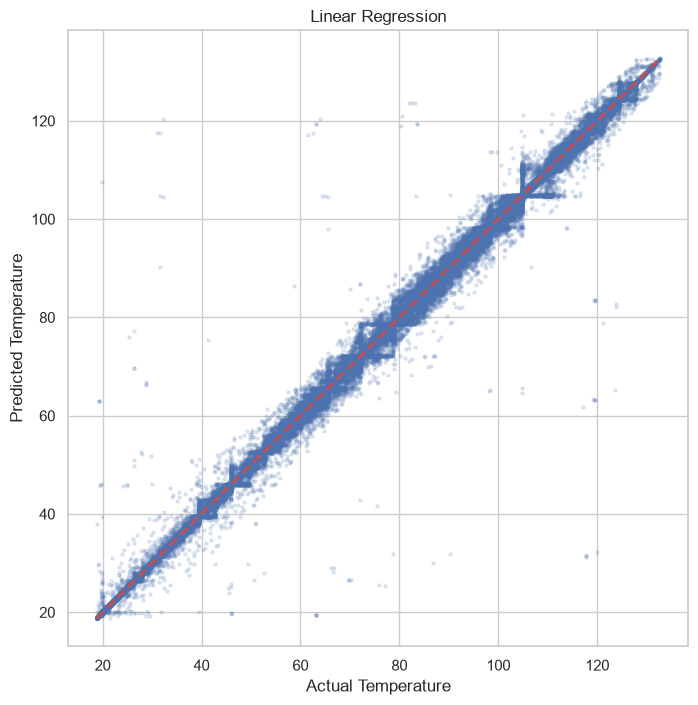

In [80]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,8))

plt.scatter(
    y_test,
    pred_lr,
    alpha=0.15,
    s=5
)

xmin = min(y_test)
xmax = max(y_test)

plt.plot(
    [xmin, xmax],
    [xmin, xmax],
    'r--',
    linewidth=2
)

plt.xlabel("Actual Temperature")

plt.ylabel("Predicted Temperature")

plt.title("Linear Regression")

plt.show()

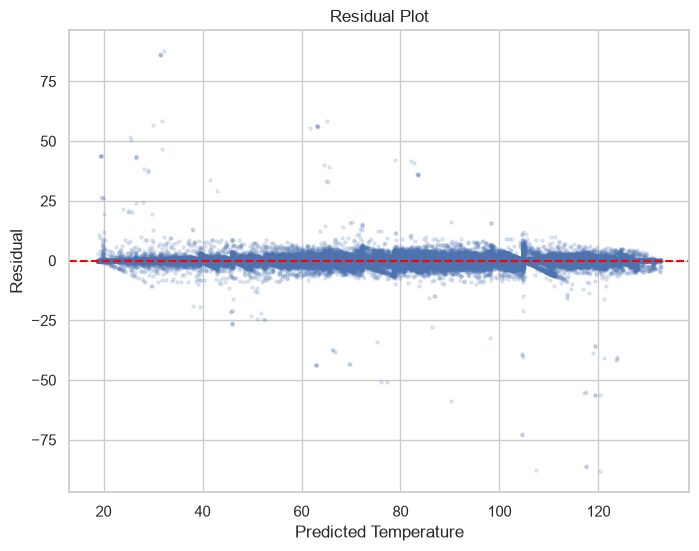

In [81]:
residual = y_test - pred_lr

plt.figure(figsize=(8,6))

plt.scatter(
    pred_lr,
    residual,
    alpha=0.15,
    s=5
)

plt.axhline(
    0,
    color='red',
    linestyle='--'
)

plt.xlabel("Predicted Temperature")

plt.ylabel("Residual")

plt.title("Residual Plot")

plt.show()

In [82]:
results = pd.DataFrame({

    "Model":["Linear Regression"],

    "RMSE":[rmse_lr],

    "MAE":[mae_lr],

    "R2":[r2_lr]

})

results

,Model,RMSE,MAE,R2
0,Linear Regression,1.078926,0.220802,0.998735


In [83]:
from sklearn.ensemble import RandomForestRegressor

In [84]:
rf = RandomForestRegressor(

    n_estimators=300,

    max_depth=20,

    min_samples_leaf=2,

    random_state=42,

    n_jobs=-1

)

In [85]:
rf.fit(
    X_train,
    y_train
)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",20
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",2
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max

In [86]:
pred_rf = rf.predict(
    X_test
)

In [87]:
rmse_rf = np.sqrt(
    mean_squared_error(
        y_test,
        pred_rf
    )
)

mae_rf = mean_absolute_error(
    y_test,
    pred_rf
)

r2_rf = r2_score(
    y_test,
    pred_rf
)

print("Random Forest")

print("---------------------")

print("RMSE :",rmse_rf)

print("MAE :",mae_rf)

print("R² :",r2_rf)

Random Forest
---------------------
RMSE : 1.4847853771536548
MAE : 0.4018466931226204
R² : 0.9976049199925164


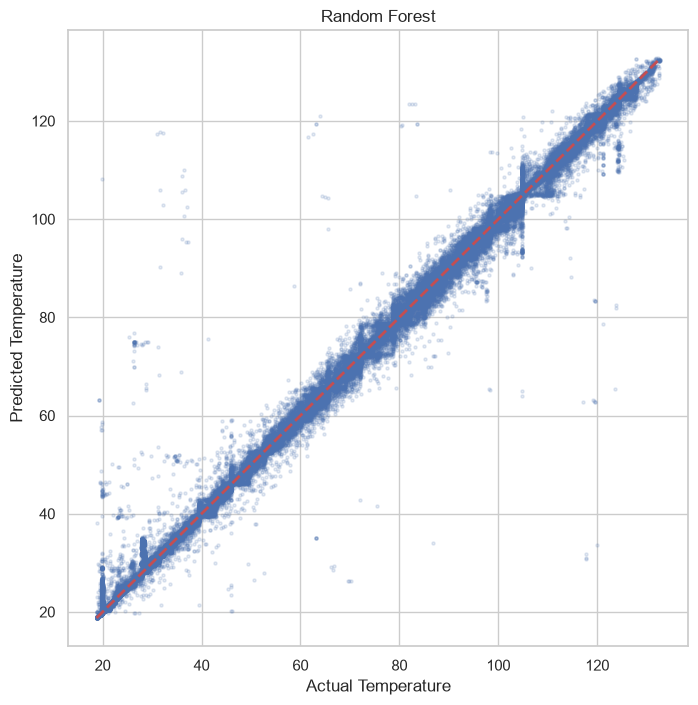

In [88]:
plt.figure(figsize=(8,8))

plt.scatter(

    y_test,

    pred_rf,

    alpha=0.15,

    s=5

)

xmin=min(y_test)

xmax=max(y_test)

plt.plot(

[xmin,xmax],

[xmin,xmax],

'r--',

linewidth=2

)

plt.xlabel("Actual Temperature")

plt.ylabel("Predicted Temperature")

plt.title("Random Forest")

plt.show()

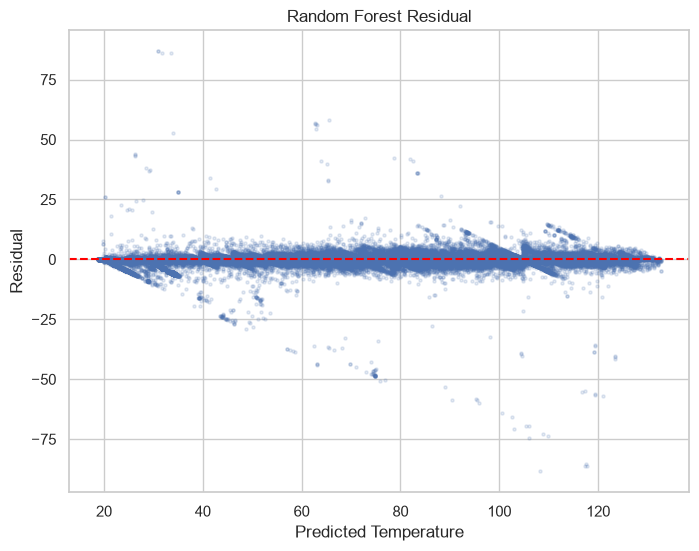

In [89]:
residual_rf = y_test-pred_rf

plt.figure(figsize=(8,6))

plt.scatter(

pred_rf,

residual_rf,

alpha=0.15,

s=5

)

plt.axhline(

0,

color='red',

linestyle='--'

)

plt.xlabel("Predicted Temperature")

plt.ylabel("Residual")

plt.title("Random Forest Residual")

plt.show()

In [90]:
importance = pd.DataFrame({

"Feature":features,

"Importance":rf.feature_importances_

})

importance = importance.sort_values(

"Importance",

ascending=False

)

importance

,Feature,Importance
6,T_prev,0.999022
4,coolant,0.000340
5,ambient,0.000149
0,current_magnitude,0.000146
1,voltage_magnitude,0.000118
2,omega,0.000114
3,torque,0.000111


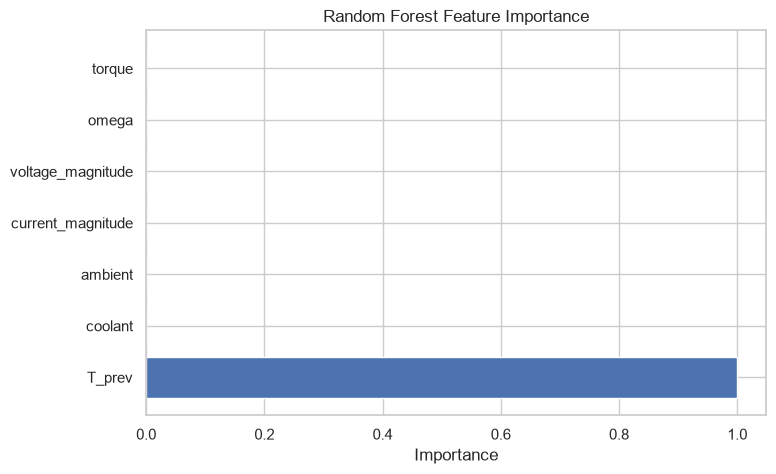

In [91]:
plt.figure(figsize=(8,5))

plt.barh(

importance["Feature"],

importance["Importance"]

)

plt.xlabel("Importance")

plt.title("Random Forest Feature Importance")

plt.show()

In [92]:
results.loc[len(results)] = [

"Random Forest",

rmse_rf,

mae_rf,

r2_rf

]

results

,Model,RMSE,MAE,R2
0,Linear Regression,1.078926,0.220802,0.998735
1,Random Forest,1.484785,0.401847,0.997605


In [93]:
!pip -q install xgboost

In [94]:
from xgboost import XGBRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import numpy as np

In [95]:
xgb = XGBRegressor(

    n_estimators=300,

    learning_rate=0.05,

    max_depth=8,

    subsample=0.8,

    colsample_bytree=0.8,

    objective="reg:squarederror",

    random_state=42,

    tree_method="hist",

    n_jobs=-1

)

In [96]:
%%time

xgb.fit(
    X_train,
    y_train
)

CPU times: total: 1min 32s
Wall time: 16.4 s


,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.8
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [97]:
pred_xgb = xgb.predict(
    X_test
)

In [98]:
rmse_xgb = np.sqrt(
    mean_squared_error(
        y_test,
        pred_xgb
    )
)

mae_xgb = mean_absolute_error(
    y_test,
    pred_xgb
)

r2_xgb = r2_score(
    y_test,
    pred_xgb
)

print("XGBoost")
print("------------------")
print("RMSE :", rmse_xgb)
print("MAE  :", mae_xgb)
print("R²   :", r2_xgb)

XGBoost
------------------
RMSE : 2.646572869723056
MAE  : 1.6300025940787926
R²   : 0.992390425479784


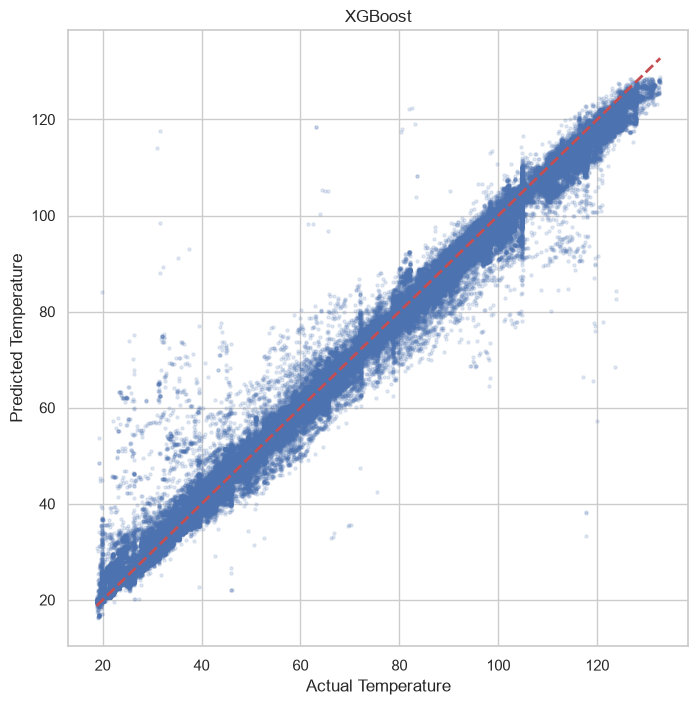

In [99]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,8))

plt.scatter(
    y_test,
    pred_xgb,
    alpha=0.15,
    s=5
)

xmin = min(y_test)
xmax = max(y_test)

plt.plot(
    [xmin, xmax],
    [xmin, xmax],
    'r--',
    linewidth=2
)

plt.xlabel("Actual Temperature")

plt.ylabel("Predicted Temperature")

plt.title("XGBoost")

plt.show()

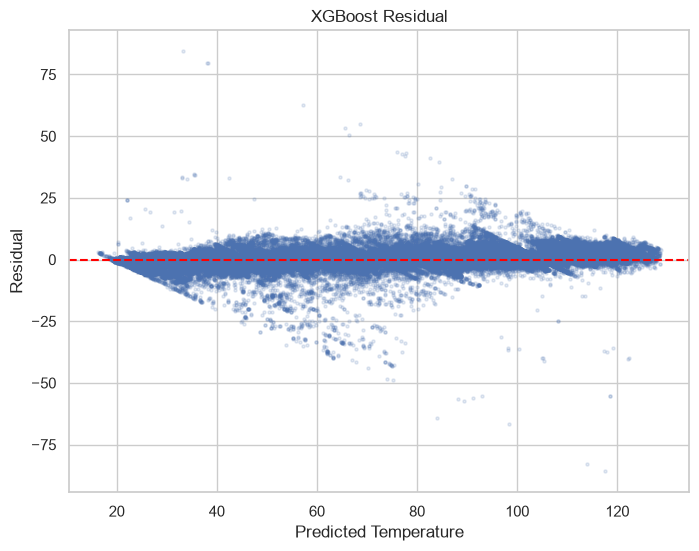

In [100]:
residual_xgb = y_test - pred_xgb

plt.figure(figsize=(8,6))

plt.scatter(
    pred_xgb,
    residual_xgb,
    alpha=0.15,
    s=5
)

plt.axhline(
    0,
    color='red',
    linestyle='--'
)

plt.xlabel("Predicted Temperature")

plt.ylabel("Residual")

plt.title("XGBoost Residual")

plt.show()

In [101]:
results.loc[len(results)] = [

    "XGBoost",

    rmse_xgb,

    mae_xgb,

    r2_xgb

]

results

,Model,RMSE,MAE,R2
0,Linear Regression,1.078926,0.220802,0.998735
1,Random Forest,1.484785,0.401847,0.997605
2,XGBoost,2.646573,1.630003,0.992390


In [102]:
importance = pd.DataFrame({

    "Feature": features,

    "Importance": xgb.feature_importances_

})

importance = importance.sort_values(
    "Importance",
    ascending=False
)

importance

,Feature,Importance
6,T_prev,0.561963
4,coolant,0.154023
0,current_magnitude,0.118302
3,torque,0.057092
2,omega,0.048973
1,voltage_magnitude,0.046198
5,ambient,0.013449


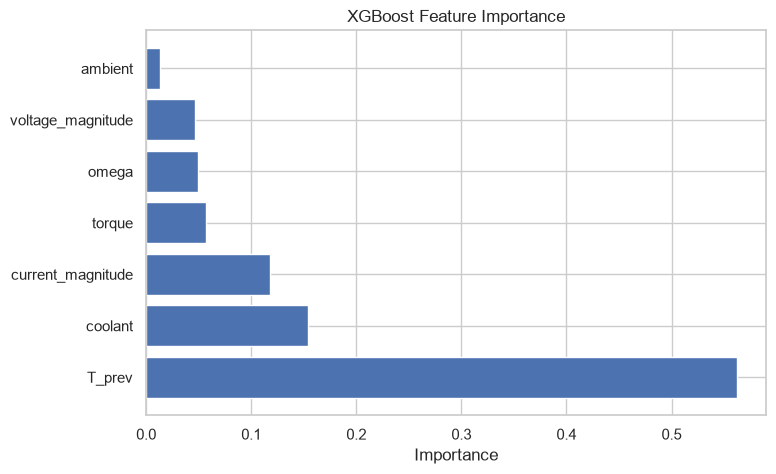

In [103]:
plt.figure(figsize=(8,5))

plt.barh(
    importance["Feature"],
    importance["Importance"]
)

plt.xlabel("Importance")

plt.title("XGBoost Feature Importance")

plt.show()

In [104]:
!pip -q install tensorflow

In [105]:
import tensorflow as tf

from tensorflow.keras import layers

from tensorflow.keras.models import Model

import numpy as np

import matplotlib.pyplot as plt

In [106]:
X_train_nn = X_train_scaled.astype(np.float32)

X_test_nn = X_test_scaled.astype(np.float32)

y_train_nn = y_train.values.astype(np.float32)

y_test_nn = y_test.values.astype(np.float32)

In [107]:
physics_train = physics_df.loc[train_idx,
[
"I_squared",

"omega_squared",

"torque_omega",

"cooling_term",

"ambient_term"

]].values.astype(np.float32)

physics_test = physics_df.loc[test_idx,
[
"I_squared",

"omega_squared",

"torque_omega",

"cooling_term",

"ambient_term"

]].values.astype(np.float32)

In [108]:
inputs = layers.Input(shape=(X_train_nn.shape[1],))

x = layers.Dense(128,activation='relu')(inputs)

x = layers.Dense(64,activation='relu')(x)

x = layers.Dense(32,activation='relu')(x)

outputs = layers.Dense(1)(x)

model = Model(inputs,outputs)

In [109]:
def physics_loss(y_true,y_pred):

    mse = tf.reduce_mean(
        tf.square(y_true-y_pred)
    )

    return mse

In [110]:
model.compile(

optimizer='adam',

loss=physics_loss,

metrics=['mae']

)

In [111]:
history = model.fit(

X_train_nn,

y_train_nn,

epochs=40,

batch_size=4096,

validation_split=0.2,

verbose=1

)

Epoch 1/40
201/201 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - loss: 1270.4189 - mae: 22.8253 - val_loss: 100.2547 - val_mae: 7.7011
Epoch 2/40
201/201 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 43.0778 - mae: 4.5898 - val_loss: 25.7476 - val_mae: 3.7315
Epoch 3/40
201/201 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 14.8609 - mae: 2.6236 - val_loss: 11.8051 - val_mae: 2.4848
Epoch 4/40
201/201 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 6.9100 - mae: 1.6733 - val_loss: 5.2229 - val_mae: 1.5350
Epoch 5/40
201/201 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 3.3791 - mae: 1.0088 - val_loss: 2.9339 - val_mae: 1.0983
Epoch 6/40
201/201 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 2.1085 - mae: 0.6959 - val_loss: 2.2057 - val_mae: 0.9193
Epoch 7/40
201/201 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 1.7705 - mae: 0.5729 - val_loss: 1.8377 - val_mae: 0.7900
Epoch 8/40
201/201 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 1.6225 - mae: 0.4954 - val_loss: 1.6567 - val_mae: 0.7207
Epoch 9/40
201/201 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms

In [112]:
pred_nn = model.predict(

X_test_nn

).flatten()

9513/9513 ━━━━━━━━━━━━━━━━━━━━ 9s 918us/step


In [113]:
rmse_nn = np.sqrt(

mean_squared_error(

y_test_nn,

pred_nn

)

)

mae_nn = mean_absolute_error(

y_test_nn,

pred_nn

)

r2_nn = r2_score(

y_test_nn,

pred_nn

)

print("Neural Network")

print("----------------")

print("RMSE :",rmse_nn)

print("MAE :",mae_nn)

print("R² :",r2_nn)

Neural Network
----------------
RMSE : 1.0944795083035472
MAE : 0.3638284504413605
R² : 0.9986985921859741


In [114]:
import os

MODEL_DIR = "models"
os.makedirs(MODEL_DIR, exist_ok=True)

In [115]:
import joblib

joblib.dump(rf, f"{MODEL_DIR}/random_forest.pkl")

print("Random Forest model saved successfully!")

Random Forest model saved successfully!


In [116]:
joblib.dump(xgb, f"{MODEL_DIR}/xgboost.pkl")

['models/xgboost.pkl']

In [117]:
xgb.save_model(f"{MODEL_DIR}/xgboost.json")

In [ ]:
joblib.dump(linear, f"{MODEL_DIR}/linear_regression.pkl")

['models/linear_regression.pkl']

In [118]:
joblib.dump(scaler, f"{MODEL_DIR}/scaler.pkl")

['models/scaler.pkl']

In [119]:
joblib.dump(features, f"{MODEL_DIR}/feature_columns.pkl")

['models/feature_columns.pkl']

In [120]:
model.save(f"{MODEL_DIR}/piml_model.keras")

In [121]:
new_data = pd.DataFrame([{
    "current_magnitude": 45,
    "voltage_magnitude": 300,
    "omega": 220,
    "torque": 50,
    "coolant": 28,
    "ambient": 25,
    "T_prev": 42
}])

new_scaled = scaler.transform(new_data)

prediction = linear.predict(new_scaled)

print("Predicted Temperature:", prediction[0])

Predicted Temperature: 41.94802611269083


# SHAP Explainer

In [125]:
import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

feature_names = X_train.columns.tolist()

# Convert scaled arrays back to DataFrames
X_train_shap = pd.DataFrame(
    X_train_scaled,
    columns=feature_names
)

X_test_shap = pd.DataFrame(
    X_test_scaled,
    columns=feature_names
)

print("="*60)
print("Initializing SHAP Explainer")
print("="*60)

explainer = shap.TreeExplainer(xgb)

print("Computing SHAP values...")

shap_values = explainer.shap_values(X_test_shap)

print("Done.")
print("SHAP Shape :", np.array(shap_values).shape)

Initializing SHAP Explainer
Computing SHAP values...
Done.
SHAP Shape : (304393, 7)


GLOBAL FEATURE IMPORTANCE


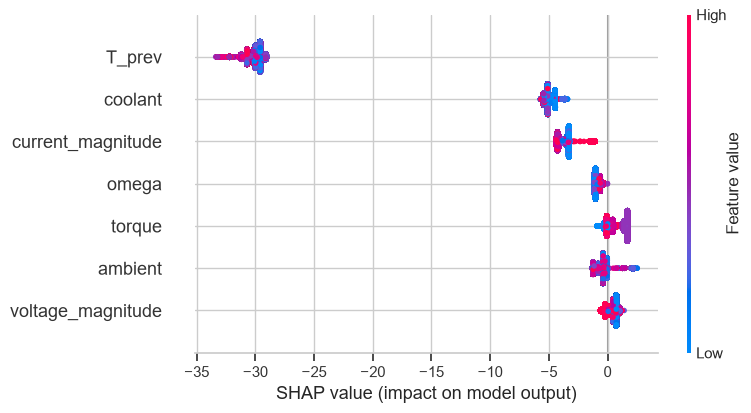

In [126]:
print("=" * 60)
print("GLOBAL FEATURE IMPORTANCE")
print("=" * 60)

shap.summary_plot(
    shap_values,
    X_test_scaled,
    feature_names=feature_names,
    show=False
)

plt.tight_layout()
plt.show()

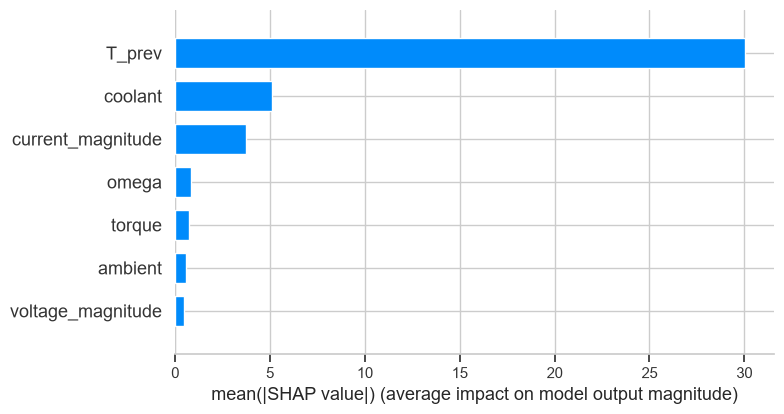

In [127]:
shap.summary_plot(
    shap_values,
    X_test_scaled,
    feature_names=feature_names,
    plot_type="bar",
    show=False
)

plt.tight_layout()
plt.show()

In [128]:
importance = np.abs(shap_values).mean(axis=0)

importance_df = pd.DataFrame({

    "Feature": feature_names,
    "Mean |SHAP|": importance

})

importance_df = importance_df.sort_values(
    by="Mean |SHAP|",
    ascending=False
).reset_index(drop=True)

importance_df

,Feature,Mean |SHAP|
0,T_prev,30.059315
1,coolant,5.091576
2,current_magnitude,3.758061
3,omega,0.831922
4,torque,0.719207
5,ambient,0.585843
6,voltage_magnitude,0.481185


In [129]:
print("=" * 60)
print("GLOBAL FEATURE RANKING")
print("=" * 60)

for i, row in importance_df.iterrows():

    print(f"{i+1:02d}. {row.Feature:<25} {row['Mean |SHAP|']:.4f}")

GLOBAL FEATURE RANKING
01. T_prev                    30.0593
02. coolant                   5.0916
03. current_magnitude         3.7581
04. omega                     0.8319
05. torque                    0.7192
06. ambient                   0.5858
07. voltage_magnitude         0.4812



Generating dependence plot for T_prev


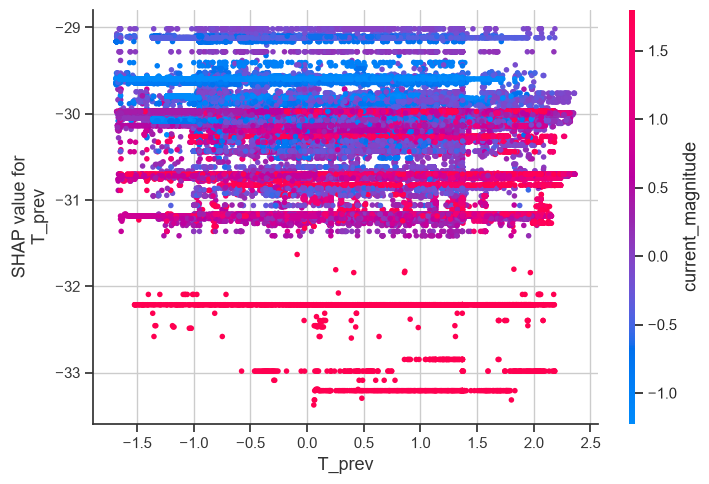


Generating dependence plot for coolant


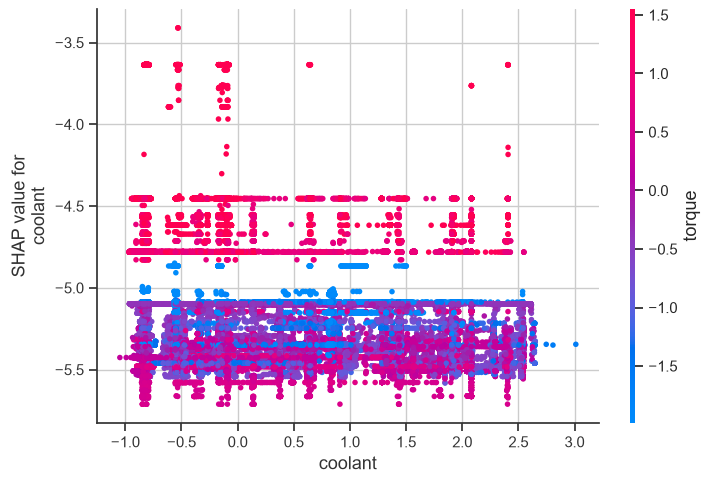


Generating dependence plot for current_magnitude


c:\Users\ARJUN MITRA\.conda\envs\piml_motor\Lib\site-packages\numpy\lib\_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
c:\Users\ARJUN MITRA\.conda\envs\piml_motor\Lib\site-packages\numpy\lib\_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


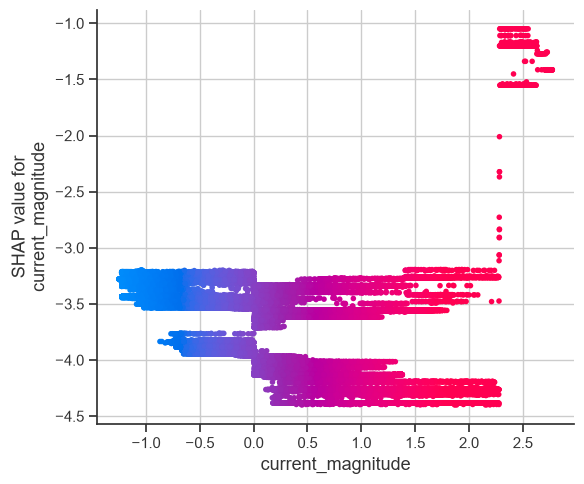


Generating dependence plot for omega


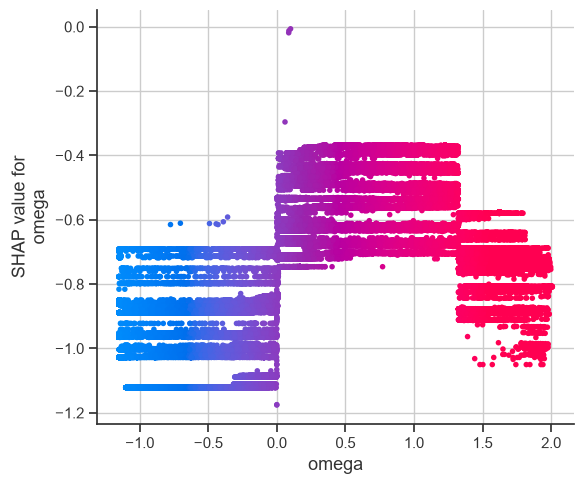


Generating dependence plot for torque


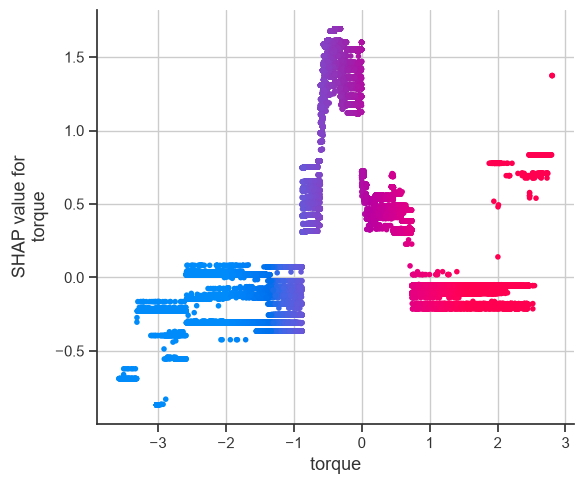


Generating dependence plot for ambient


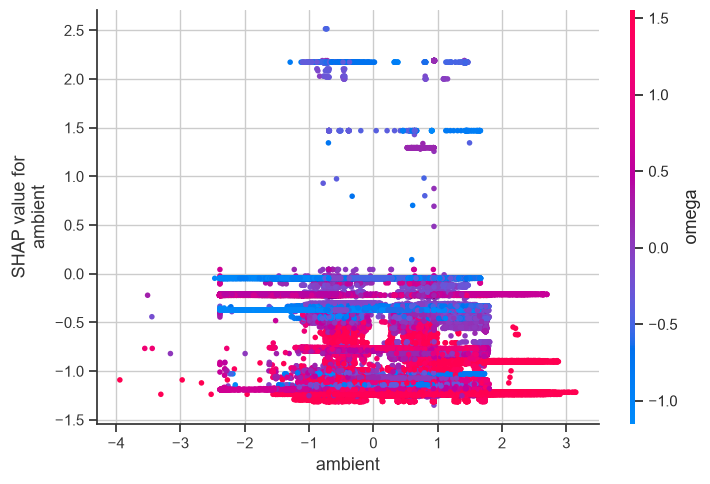

In [130]:
top_features = importance_df["Feature"].head(6)

for feature in top_features:

    print(f"\nGenerating dependence plot for {feature}")

    shap.dependence_plot(
        feature,
        shap_values,
        X_test_scaled,
        feature_names=feature_names,
        interaction_index="auto",
        show=False
    )

    plt.tight_layout()
    plt.show()

In [131]:
print("=" * 70)
print("GLOBAL ENGINEERING INTERPRETATION")
print("=" * 70)

for rank, row in importance_df.iterrows():

    feature = row["Feature"]

    score = row["Mean |SHAP|"]

    print(f"\n{rank+1}. {feature}")

    print(f"Average SHAP Contribution : {score:.4f}")

    if feature == "T_prev":

        print("Reason : Thermal inertia dominates winding temperature.")

    elif feature in ["current_magnitude","I_squared"]:

        print("Reason : Copper loss increases with stator current.")

    elif feature == "coolant":

        print("Reason : Coolant removes heat from stator winding.")

    elif feature == "ambient":

        print("Reason : Ambient affects overall cooling capability.")

    elif feature in ["omega","speed"]:

        print("Reason : Speed influences motor losses and cooling.")

    elif feature == "torque":

        print("Reason : Mechanical loading contributes to heat generation.")

    else:

        print("Reason : Learned from operating data.")

GLOBAL ENGINEERING INTERPRETATION

1. T_prev
Average SHAP Contribution : 30.0593
Reason : Thermal inertia dominates winding temperature.

2. coolant
Average SHAP Contribution : 5.0916
Reason : Coolant removes heat from stator winding.

3. current_magnitude
Average SHAP Contribution : 3.7581
Reason : Copper loss increases with stator current.

4. omega
Average SHAP Contribution : 0.8319
Reason : Speed influences motor losses and cooling.

5. torque
Average SHAP Contribution : 0.7192
Reason : Mechanical loading contributes to heat generation.

6. ambient
Average SHAP Contribution : 0.5858
Reason : Ambient affects overall cooling capability.

7. voltage_magnitude
Average SHAP Contribution : 0.4812
Reason : Learned from operating data.


Explainable Engineering Decision Support System

Engineering Groups

In [132]:
ENGINEERING_GROUPS = {

    "Thermal Memory": [
        "T_prev"
    ],

    "Electrical Heating": [
        "current_magnitude",
        "voltage_magnitude"
    ],

    "Mechanical Loading": [
        "omega",
        "torque"
    ],

    "Cooling": [
        "coolant"
    ],

    "Environment": [
        "ambient"
    ]
}

In [133]:
feature_to_group = {}

for group, features in ENGINEERING_GROUPS.items():

    for feature in features:

        feature_to_group[feature] = group

feature_to_group

{'T_prev': 'Thermal Memory',
 'current_magnitude': 'Electrical Heating',
 'voltage_magnitude': 'Electrical Heating',
 'omega': 'Mechanical Loading',
 'torque': 'Mechanical Loading',
 'coolant': 'Cooling',
 'ambient': 'Environment'}

In [134]:
import numpy as np
import pandas as pd


def engineering_diagnosis(feature_names, shap_row):

    df = pd.DataFrame({

        "Feature": feature_names,
        "SHAP": shap_row

    })

    df["Engineering Group"] = df["Feature"].map(feature_to_group)

    group_df = (

        df.groupby("Engineering Group")["SHAP"]

        .sum()

        .reset_index()

    )

    group_df["Abs"] = group_df["SHAP"].abs()

    group_df = group_df.sort_values(

        "Abs",

        ascending=False

    ).reset_index(drop=True)

    return df, group_df

In [135]:
def explain_engineering(group_df):

    explanation = []

    for _, row in group_df.iterrows():

        group = row["Engineering Group"]

        contribution = row["SHAP"]

        if abs(contribution) < 0.05:
            continue

        if group == "Thermal Memory":

            explanation.append(
                f"Residual heat stored in the stator winding is the dominant contributor ({contribution:.2f}°C)."
            )

        elif group == "Electrical Heating":

            explanation.append(
                f"Electrical loading increases copper losses and contributes {contribution:.2f}°C."
            )

        elif group == "Cooling":

            if contribution > 0:

                explanation.append(
                    f"Cooling conditions are insufficient, increasing temperature by {contribution:.2f}°C."
                )

            else:

                explanation.append(
                    f"Cooling effectively reduces temperature by {abs(contribution):.2f}°C."
                )

        elif group == "Mechanical Loading":

            explanation.append(
                f"Mechanical loading contributes {contribution:.2f}°C through motor operation."
            )

        elif group == "Environment":

            explanation.append(
                f"Ambient conditions influence temperature by {contribution:.2f}°C."
            )

    return explanation

In [136]:
def recommend_actions(group_df):

    recommendations = []

    dominant = group_df.iloc[0]["Engineering Group"]

    if dominant == "Thermal Memory":

        recommendations.append(
            "Allow additional cooling time before increasing load."
        )

    if dominant == "Electrical Heating":

        recommendations.append(
            "Reduce stator current or operating load."
        )

    if dominant == "Cooling":

        recommendations.append(
            "Inspect coolant temperature and cooling efficiency."
        )

    if dominant == "Mechanical Loading":

        recommendations.append(
            "Reduce torque demand or operating speed."
        )

    if dominant == "Environment":

        recommendations.append(
            "Improve ambient ventilation around the motor."
        )

    recommendations.append(
        "Continue monitoring winding temperature."
    )

    return recommendations

In [139]:
def risk_level(temp):

    if temp < 60:
        return "LOW"

    elif temp < 90:
        return "MODERATE"

    elif temp < 110:
        return "HIGH"

    else:
        return "CRITICAL"

In [140]:
def predict_temperature_and_explain(sample):

    sample_df = pd.DataFrame(

        [sample],

        columns=feature_names

    )

    sample_scaled = scaler.transform(sample_df)

    prediction = xgb.predict(sample_scaled)[0]

    shap_value = explainer.shap_values(sample_scaled)[0]

    feature_df, group_df = engineering_diagnosis(

        feature_names,

        shap_value

    )

    feature_df["Abs"] = feature_df["SHAP"].abs()

    feature_df = feature_df.sort_values(

        "Abs",

        ascending=False

    )

    explanation = explain_engineering(group_df)

    recommendations = recommend_actions(group_df)

    print("=" * 65)

    print("PMSM THERMAL DECISION REPORT")

    print("=" * 65)

    print(f"\nPredicted Temperature : {prediction:.2f} °C")

    print(f"Risk Level            : {risk_level(prediction)}")

    print("\nMajor Feature Contributions")

    for _, row in feature_df.iterrows():

        print(

            f"{row.Feature:<20}"

            f"{row.SHAP:>8.3f}"

        )

    print("\nEngineering Categories")

    print(group_df)

    print("\nEngineering Diagnosis")

    for item in explanation:

        print("•", item)

    print("\nRecommendations")

    for item in recommendations:

        print("•", item)

    print("=" * 65)

    return prediction, feature_df, group_df

In [141]:
sample = X_test.iloc[0]

prediction, feature_df, group_df = predict_temperature_and_explain(sample)

PMSM THERMAL DECISION REPORT

Predicted Temperature : 26.75 °C
Risk Level            : LOW

Major Feature Contributions
T_prev               -29.974
coolant               -4.454
current_magnitude     -4.263
omega                 -1.122
voltage_magnitude      0.468
torque                -0.056
ambient               -0.046

Engineering Categories
    Engineering Group       SHAP        Abs
0      Thermal Memory -29.974174  29.974174
1             Cooling  -4.454180   4.454180
2  Electrical Heating  -3.794298   3.794298
3  Mechanical Loading  -1.177103   1.177103
4         Environment  -0.046284   0.046284

Engineering Diagnosis
• Residual heat stored in the stator winding is the dominant contributor (-29.97°C).
• Cooling effectively reduces temperature by 4.45°C.
• Electrical loading increases copper losses and contributes -3.79°C.
• Mechanical loading contributes -1.18°C through motor operation.

Recommendations
• Allow additional cooling time before increasing load.
• Continue monitori

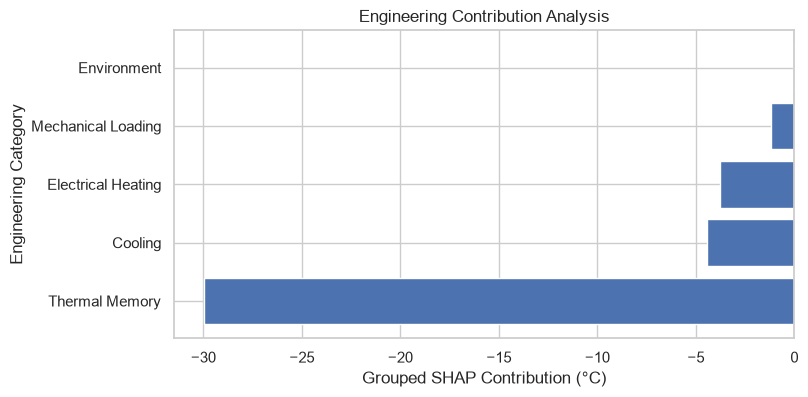

In [142]:
plt.figure(figsize=(8,4))

plt.barh(

    group_df["Engineering Group"],

    group_df["SHAP"]

)

plt.xlabel("Grouped SHAP Contribution (°C)")

plt.ylabel("Engineering Category")

plt.title("Engineering Contribution Analysis")

plt.grid(True)

plt.show()

In [143]:
results = []

for i in range(100):

    sample = X_test.iloc[i]

    sample_scaled = scaler.transform(pd.DataFrame([sample], columns=feature_names))

    pred = xgb.predict(sample_scaled)[0]

    shap_row = explainer.shap_values(sample_scaled)[0]

    _, group_df = engineering_diagnosis(feature_names, shap_row)

    dominant = group_df.iloc[0]["Engineering Group"]

    results.append({

        "Prediction": pred,
        "Dominant Cause": dominant

    })

batch_results = pd.DataFrame(results)

batch_results.head()

,Prediction,Dominant Cause
0,26.754936,Thermal Memory
1,26.754936,Thermal Memory
2,29.268879,Thermal Memory
3,29.268879,Thermal Memory
4,29.268879,Thermal Memory


Dominant Cause
Thermal Memory    100
Name: count, dtype: int64


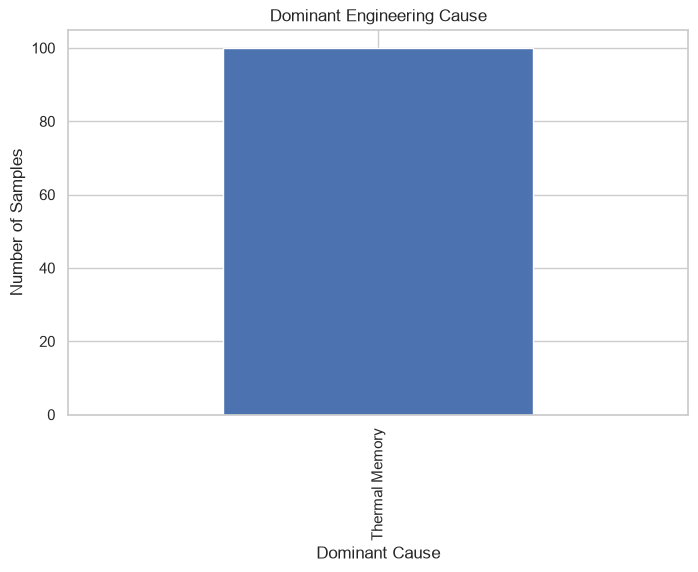

In [144]:
cause_counts = batch_results["Dominant Cause"].value_counts()

print(cause_counts)

plt.figure(figsize=(8,5))

cause_counts.plot(kind="bar")

plt.ylabel("Number of Samples")

plt.title("Dominant Engineering Cause")

plt.grid(True)

plt.show()

Risk
LOW    100
Name: count, dtype: int64


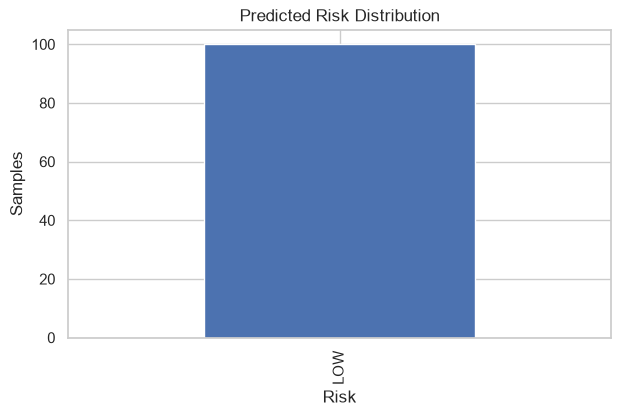

In [145]:
batch_results["Risk"] = batch_results["Prediction"].apply(risk_level)

risk_counts = batch_results["Risk"].value_counts()

print(risk_counts)

plt.figure(figsize=(7,4))

risk_counts.plot(kind="bar")

plt.ylabel("Samples")

plt.title("Predicted Risk Distribution")

plt.grid(True)

plt.show()

In [146]:
group_summary = []

for i in range(len(X_test)):

    sample = X_test.iloc[i]

    scaled = scaler.transform(pd.DataFrame([sample], columns=feature_names))

    shap_row = explainer.shap_values(scaled)[0]

    _, group_df = engineering_diagnosis(feature_names, shap_row)

    group_summary.append(

        group_df.set_index("Engineering Group")["SHAP"]

    )

group_summary = pd.DataFrame(group_summary)

group_summary = group_summary.fillna(0)

group_summary.mean()

Engineering Group
Thermal Memory       -30.097023
Cooling               -5.084947
Electrical Heating    -3.372097
Mechanical Loading    -0.200003
Environment           -0.552706
dtype: float32

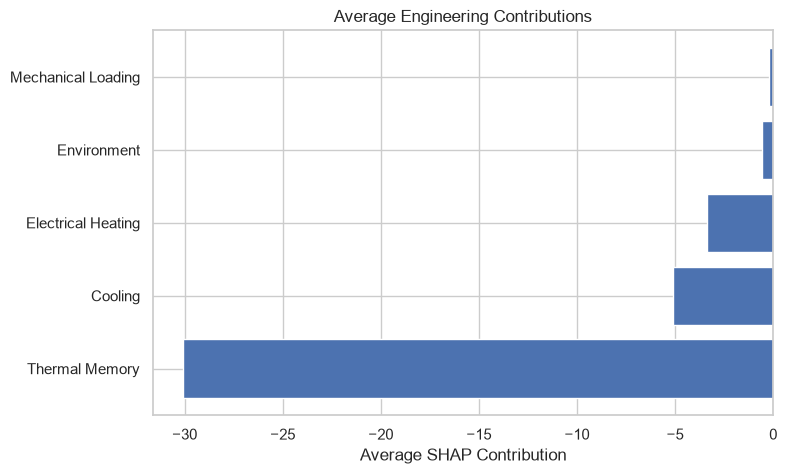

In [147]:
avg = group_summary.mean().sort_values()

plt.figure(figsize=(8,5))

plt.barh(avg.index, avg.values)

plt.xlabel("Average SHAP Contribution")

plt.title("Average Engineering Contributions")

plt.grid(True)

plt.show()

In [148]:
batch_results.to_csv(

    "Engineering_Report.csv",

    index=False

)

print("Engineering report exported.")

Engineering report exported.


In [149]:
for i in range(5):

    print("\n")

    print("="*70)

    print(f"SAMPLE {i}")

    predict_temperature_and_explain(X_test.iloc[i])



SAMPLE 0
PMSM THERMAL DECISION REPORT

Predicted Temperature : 26.75 °C
Risk Level            : LOW

Major Feature Contributions
T_prev               -29.974
coolant               -4.454
current_magnitude     -4.263
omega                 -1.122
voltage_magnitude      0.468
torque                -0.056
ambient               -0.046

Engineering Categories
    Engineering Group       SHAP        Abs
0      Thermal Memory -29.974174  29.974174
1             Cooling  -4.454180   4.454180
2  Electrical Heating  -3.794298   3.794298
3  Mechanical Loading  -1.177103   1.177103
4         Environment  -0.046284   0.046284

Engineering Diagnosis
• Residual heat stored in the stator winding is the dominant contributor (-29.97°C).
• Cooling effectively reduces temperature by 4.45°C.
• Electrical loading increases copper losses and contributes -3.79°C.
• Mechanical loading contributes -1.18°C through motor operation.

Recommendations
• Allow additional cooling time before increasing load.
• Contin

Counterfactual Analysis

In [150]:
def counterfactual_prediction(sample, feature, percent_change):

    sample_cf = sample.copy()

    sample_cf[feature] *= (1 + percent_change / 100)

    sample_df = pd.DataFrame([sample], columns=feature_names)
    sample_cf_df = pd.DataFrame([sample_cf], columns=feature_names)

    sample_scaled = scaler.transform(sample_df)
    sample_cf_scaled = scaler.transform(sample_cf_df)

    original_temp = xgb.predict(sample_scaled)[0]
    new_temp = xgb.predict(sample_cf_scaled)[0]

    delta = new_temp - original_temp

    return original_temp, new_temp, delta

In [169]:
SCENARIOS = {

    "Reduce Current (-50%)":
        ("current_magnitude", -50),

    "Reduce Speed (-50%)":
        ("omega", -50),

    "Reduce Torque (-50%)":
        ("torque", -50),

    "Reduce Coolant Temperature (-50%)":
        ("coolant", -50),

    "Reduce Ambient Temperature (-50%)":
        ("ambient", -50)

}

In [170]:
def evaluate_counterfactuals(sample):

    rows = []

    for scenario in SCENARIOS:

        feature, change = SCENARIOS[scenario]

        old_temp, new_temp, delta = counterfactual_prediction(
            sample,
            feature,
            change
        )

        rows.append({

            "Scenario": scenario,

            "Original Temp": old_temp,

            "New Temp": new_temp,

            "Temperature Change": delta

        })

    df = pd.DataFrame(rows)

    df = df.sort_values(
        "Temperature Change"
    )

    return df

In [171]:
sample = X_test.iloc[0]

cf = evaluate_counterfactuals(sample)

cf

,Scenario,Original Temp,New Temp,Temperature Change
2,Reduce Torque (-50%),26.754936,26.014526,-0.740410
1,Reduce Speed (-50%),26.754936,26.754936,0.000000
3,Reduce Coolant Temperature (-50%),26.754936,26.754936,0.000000
4,Reduce Ambient Temperature (-50%),26.754936,26.754936,0.000000
0,Reduce Current (-50%),26.754936,27.106615,0.351679


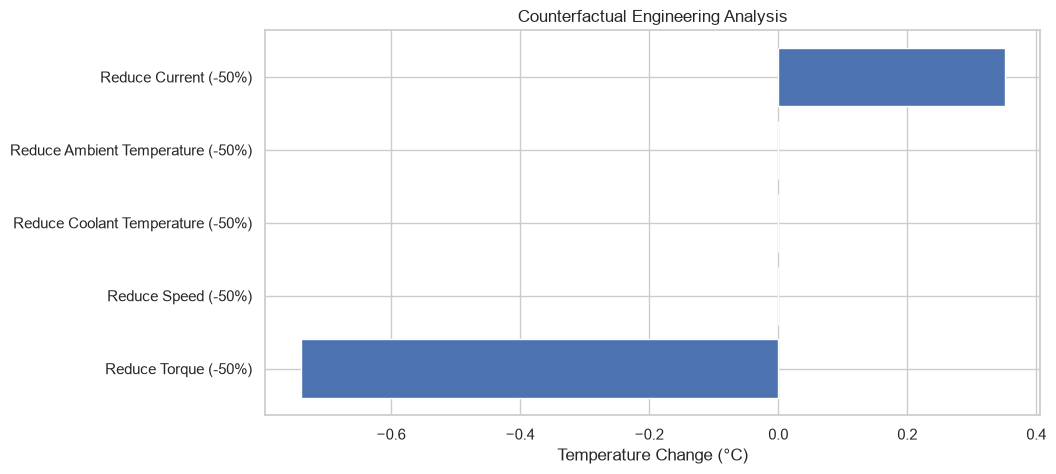

In [172]:
plt.figure(figsize=(10,5))

plt.barh(

    cf["Scenario"],

    cf["Temperature Change"]

)

plt.xlabel("Temperature Change (°C)")

plt.title("Counterfactual Engineering Analysis")

plt.grid(True)

plt.show()

In [173]:
def engineering_decision(counterfactual_df):

    best = counterfactual_df.iloc[0]

    print("="*65)

    print("ENGINEERING DECISION SUPPORT")

    print("="*65)

    print()

    print("Best Action")

    print(best["Scenario"])

    print()

    print(

        f"Expected Temperature Reduction : "

        f"{abs(best['Temperature Change']):.2f} °C"

    )

    print()

    print("Priority Ranking")

    print()

    for i, row in counterfactual_df.iterrows():

        print(

            f"{i+1}. "

            f"{row['Scenario']}"

            f" ({row['Temperature Change']:.2f} °C)"

        )

In [174]:
engineering_decision(cf)

ENGINEERING DECISION SUPPORT

Best Action
Reduce Torque (-50%)

Expected Temperature Reduction : 0.74 °C

Priority Ranking

3. Reduce Torque (-50%) (-0.74 °C)
2. Reduce Speed (-50%) (0.00 °C)
4. Reduce Coolant Temperature (-50%) (0.00 °C)
5. Reduce Ambient Temperature (-50%) (0.00 °C)
1. Reduce Current (-50%) (0.35 °C)


In [175]:
def generate_full_report(sample):

    prediction, feature_df, group_df = predict_temperature_and_explain(sample)

    print()

    print("="*70)

    print("OPTIMIZATION ANALYSIS")

    print("="*70)

    cf = evaluate_counterfactuals(sample)

    print(cf)

    print()

    engineering_decision(cf)

    return cf

In [178]:
generate_full_report(X_test.iloc[40])

PMSM THERMAL DECISION REPORT

Predicted Temperature : 26.75 °C
Risk Level            : LOW

Major Feature Contributions
T_prev               -29.974
coolant               -4.454
current_magnitude     -4.263
omega                 -1.122
voltage_magnitude      0.468
torque                -0.056
ambient               -0.046

Engineering Categories
    Engineering Group       SHAP        Abs
0      Thermal Memory -29.974174  29.974174
1             Cooling  -4.454180   4.454180
2  Electrical Heating  -3.794298   3.794298
3  Mechanical Loading  -1.177103   1.177103
4         Environment  -0.046284   0.046284

Engineering Diagnosis
• Residual heat stored in the stator winding is the dominant contributor (-29.97°C).
• Cooling effectively reduces temperature by 4.45°C.
• Electrical loading increases copper losses and contributes -3.79°C.
• Mechanical loading contributes -1.18°C through motor operation.

Recommendations
• Allow additional cooling time before increasing load.
• Continue monitori

,Scenario,Original Temp,New Temp,Temperature Change
2,Reduce Torque (-50%),26.754936,26.014526,-0.74041
0,Reduce Current (-50%),26.754936,26.754936,0.00000
1,Reduce Speed (-50%),26.754936,26.754936,0.00000
3,Reduce Coolant Temperature (-50%),26.754936,26.754936,0.00000
4,Reduce Ambient Temperature (-50%),26.754936,26.754936,0.00000


In [179]:
import joblib

joblib.dump(xgb, "model.pkl")
joblib.dump(scaler, "scaler.pkl")
joblib.dump(explainer, "explainer.pkl")
joblib.dump(feature_names, "feature_names.pkl")

['feature_names.pkl']

In [180]:
print(X_train.columns.tolist())

['current_magnitude', 'voltage_magnitude', 'omega', 'torque', 'coolant', 'ambient', 'T_prev']


In [181]:
sample = pd.DataFrame(
    [[350, 600, 6000, 300, 100, 80, 200]],
    columns=[
        "current_magnitude",
        "voltage_magnitude",
        "omega",
        "torque",
        "coolant",
        "ambient",
        "T_prev"
    ]
)

pred = xgb.predict(scaler.transform(sample))[0]

print("Prediction:", pred)

Prediction: 32.812485


In [182]:
i = 100

sample = X_test.iloc[[i]]

pred = xgb.predict(scaler.transform(sample))[0]

print("Prediction :", pred)
print("Actual      :", y_test.iloc[i])

Prediction : 26.754936
Actual      : 34.943233489990234


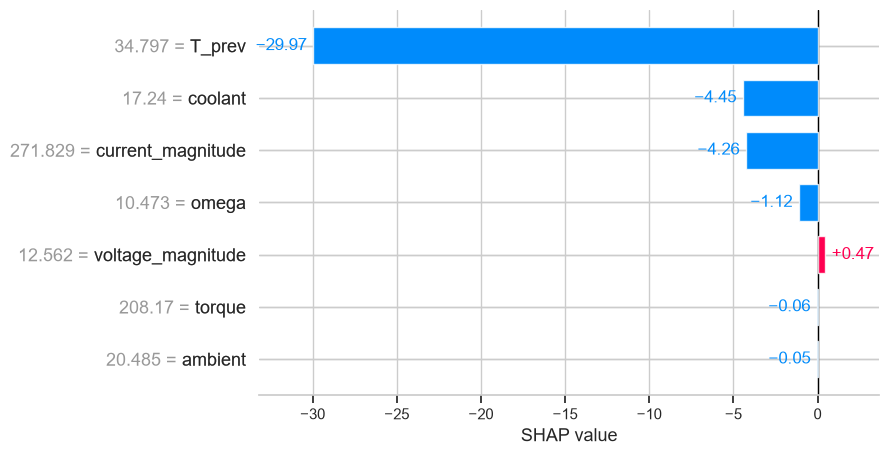

In [183]:
shap_exp = shap.Explanation(
    values=shap_values[0],
    base_values=explainer.expected_value,
    data=sample.iloc[0].values,   # use original values
    feature_names=feature_names
)

shap.plots.bar(shap_exp)

In [184]:
print(xgb.predict(scaler.transform(sample))[0])

print(scaler.mean_)

print(y_train.max())

26.754936
[106.96099816  79.79745538 228.20900444  30.03328133  36.45178312
  24.53150451  66.20089911]
141.36288452148438


In [185]:
print(X_train.describe().T[['min','max','50%']])

                          min         max         50%
current_magnitude    0.000039  361.515337  107.227463
voltage_magnitude    0.000002  134.264098   97.837845
omega              -28.855439  628.320116  196.015115
torque            -246.086203  261.005707   10.455839
coolant             10.623751   93.750795   27.653548
ambient              8.783478   30.171988   24.804794
T_prev              18.585815  141.362885   64.783965
